# M07 · Vecteurs et géométrie de ℝⁿ — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m07_vecteurs_rn/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M07.1 à M07.13, M07.19 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M07.24 | Normes Lp et similarité cosinus · `norm_p, cosine_similarity` | 🔨 | ★ | 20 |
|  | M07.25 | La projection sur une droite · `project_onto_line` | 🔨 | ★ | 15 |
|  | M07.26 | Barycentre et somme des carrés des distances · `centroid, sum_sq_distances_to` | 🔨 | ★ | 20 |
|  | M07.27 | Côté d'un hyperplan et distance à un hyperplan · `side_of_hyperplane, distance_to_hyperplane` | 🔨 | ★ | 20 |
|  | M07.28 | `np.linalg.norm` (ord = 1, 2, inf) et `scipy.spatial.distance` contre tes fonctions | 📦 | ★ | 10 |
| B | M07.29 | Prédire : l'angle de deux vecteurs tirés au hasard en dimension 1 000 | 🔮 | ★ | 10 |
|  | M07.30 | La norme d'un vecteur gaussien se concentre autour de √d | 🔬 | ★★ | 20 |
|  | M07.31 | Médiane ou moyenne : le centre qui minimise les distances L1 ou leurs carrés, face à des points aberrants | 🔬 | ★★ | 20 |
|  | M07.32 | Les boules unités L1, L2, L∞ et Lp dans le plan | 🎨 | ★ | 20 |
| C | M07.33 | Chasse à l'erreur : une distance sans racine, un cosinus mal normalisé, une projection sur un vecteur non unitaire | 🐛 | ★ | 15 |
|  | M07.34 | Les normes de toutes les lignes d'un tableau : axis, keepdims et broadcasting | 🛠️ | ★ | 15 |
|  | M07.35 | Défi : le point qui minimise la somme des distances (non au carré) à 60 villes, à 0,1 % près | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : combinaisons linéaires et one-hot, produits scalaires, normes et distances, cosinus, projection, hyperplans, score linéaire, barycentre et inertie, silhouette, k-means++, diagonale du cube, distance moyenne dans le cube, unités et plus proche voisin.
- Écrire les sept fonctions de `mymath/vectors.py` et les tester, puis comparer avec NumPy et SciPy.
- Prédire l'angle de deux vecteurs aléatoires, mesurer la concentration de la norme, comparer médiane et moyenne, tracer les boules unités, chasser des erreurs, vectoriser des normes, trouver une médiane géométrique.

**Rappel express.** $\mathbf{u} \cdot \mathbf{v} = \sum u_i v_i$ ; $\lVert \mathbf{x} \rVert_1 = \sum |x_i|$, $\lVert \mathbf{x} \rVert_2 = \sqrt{\sum x_i^2}$, $\lVert \mathbf{x} \rVert_\infty = \max |x_i|$ ; $\cos\theta = \frac{\mathbf{u} \cdot \mathbf{v}}{\lVert \mathbf{u} \rVert\,\lVert \mathbf{v} \rVert}$ ; projection $\frac{\mathbf{x} \cdot \mathbf{u}}{\mathbf{u} \cdot \mathbf{u}}\,\mathbf{u}$ ; distance à l'hyperplan $\frac{|\mathbf{w} \cdot \mathbf{x} + b|}{\lVert \mathbf{w} \rVert}$ ; $\sum \lVert \mathbf{x}_i - \mathbf{c} \rVert^2 = \sum \lVert \mathbf{x}_i - \bar{\mathbf{x}} \rVert^2 + m\,\lVert \bar{\mathbf{x}} - \mathbf{c} \rVert^2$.

## Partie 0 · Vérifier tes exercices papier (✏️ M07.1 à M07.13, 🔗 M07.19)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"7/9"` ;
- une liste `[-1.5, 2.5, 0]` (un vecteur, un point, une liste de valeurs), `True` / `False`, ou une lettre entre guillemets, `"K"`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math

import numpy as np

P10 = np.array([(0, 0), (2, 0), (1, 2), (6, 1), (7, 3)], dtype=float)      # M07.10: A, B, C, D, F


def silhouette_10(labels, i):
    """s(i), a(i), b(i) for the points P10 with the given cluster labels."""
    labels = np.array(labels)
    d = np.sqrt(((P10 - P10[i]) ** 2).sum(axis=1))
    same = labels == labels[i]
    same[i] = False
    a = d[same].mean()
    b = min(d[labels == k].mean() for k in set(labels.tolist()) if k != labels[i])
    return (b - a) / max(a, b), a, b


S10_A, A10_A, B10_A = silhouette_10([1, 1, 1, 2, 2], 0)
S10_D, A10_D, B10_D = silhouette_10([1, 1, 1, 2, 2], 3)
S10_B = silhouette_10([1, 2, 1, 2, 2], 1)[0]

**Ex M07.1 — Combinaisons linéaires et vecteurs one-hot dans ℝ⁴**

In [3]:
wbm.record("M07.1a", [4, -1, -1, 6], mistakes={"additionne coordonnée par coordonnée : la question demande u + v, pas u − v": [-2, -3, 1, 2]})
wbm.record("M07.1b", [-7, -7, 3, 2], mistakes={"3v se retranche : 2u − 3v, coordonnée par coordonnée": [11, -1, -3, 14]})
wbm.record("M07.1c", [-2, -1, 6, 1], mistakes={"w s'ajoute : u − v + w": [-2, -5, -4, 3]})
wbm.record("M07.1d", [2, 1], mistakes={"a multiplie u et b multiplie v : l'ordre est [a, b]": [1, 2]})
wbm.record("M07.1e", [0, 0, 1, 0], mistakes={"l'ordre des modes est (vélo, bus, métro, marche) : le métro est le troisième": [0, 0, 0, 1], "le métro est le troisième mode de la liste (vélo, bus, métro, marche)": [0, 1, 0, 0]})
wbm.record("M07.1f", [4, 3, 0, 3])
wbm.record("M07.1g", [0.4, 0.3, 0, 0.3], decimals=2, mistakes={"divise chaque coordonnée par le nombre de trajets": [4, 3, 0, 3]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["a122da175516edc0fc94e4aa9155f66d3ce0861bbd3e8df1125cd9a51371197a", "169976fb3214a9074d3f94de4b43014b8da2d157ec892da7df3f46a2268dca40", "8fca691e9a151ff9d24218dea749be15412d05118273ae04b79c2cbb2162ac6e", "b7e932c9f18f55e7bc24bce743deae0f9c5f146ddd23824ff5445f5e74c8c228"], "hash": "09afed81cfca9ec400107187ba7df5cbfb393ab7ae6f45774e5e4c64fa909f33", "id": "M07.1a", "integer": true, "kind": "array", "mistakes": {"533cfdc28192fafd0daa7236db79f73cf235803df7f1d1aba3f0ddcc3383eae6": "additionne coordonnée par coordonnée : la question demande u + v, pas u − v"}, "shape": [4]}
📝 Ex M07.1a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["a8dad1a9f1a259a29c8b8182a4962d41923f59e69335610839281c6edf9073f1", "f3665902f5cb2faedfe335109980a1ea94a9030b331c2fba6eb69e07a9bb7a96", "697021b14745a487c44ecf0c65ec7644e1efc144cfa686201fd5f53f7cf32183", "5d212d8590c7075a16c9680cebd631ba3828f641364d44c33db03a000786f0cc"], "hash"

**Ex M07.2 — Produits scalaires, ‖u + v‖² et l'identité du parallélogramme**

In [4]:
wbm.record("M07.2a", 3, mistakes={"attention aux signes : (−2) × 1 est négatif": 7})
wbm.record("M07.2b", 9, mistakes={"la question demande le carré de la norme : sans racine": 3})
wbm.record("M07.2c", 12)
wbm.record("M07.2d", 36, mistakes={"le coefficient 2 s'élève au carré : ‖2u‖² = 4 ‖u‖²": 18, "le double produit −2 (2u) · v manque": 48, "regarde le signe du double produit dans (2u − v) · (2u − v)": 60, "le produit croisé compte deux fois : −2 (2u) · v = −4 u · v": 42})
wbm.record("M07.2e", "-1/4", kind="fraction", simplified=True, mistakes={"(u + t v) · v = u · v + t v · v : isole t, avec son signe": "1/4", "la condition porte sur v : c'est v · v qui apparaît, pas u · u": "-1/3"})
wbm.record("M07.2f", 8, mistakes={"la différence ‖a + b‖² − ‖a − b‖² vaut 4 a · b : divise par 4": 32, "divise par 4, pas par 2": 16, "la somme donne 2‖a‖² + 2‖b‖² ; pour a · b, fais la différence": 34})
wbm.record("M07.2g", False)

WBM_ANSWER {"hash": "e1277d8aad5bd5127ff4fecfc335cf473f6363e94822913131119528cf6c20c2", "id": "M07.2a", "kind": "int", "magnitude": 0, "mistakes": {"856e19ea213656649442c336d688668a4ff87571c563f3bd6c1e7596a4247fe0": "attention aux signes : (−2) × 1 est négatif"}, "sign": 1}
📝 Ex M07.2a : réponse enregistrée (int).
WBM_ANSWER {"hash": "5e36e856fb5399f03410df4bd537e479208cb485d636dcd973119cd362613eda", "id": "M07.2b", "kind": "int", "magnitude": 0, "mistakes": {"5841dbdcbf6b3734cedb6297d4808010f3039b5294c69060e9989cf7f531a580": "la question demande le carré de la norme : sans racine"}, "sign": 1}
📝 Ex M07.2b : réponse enregistrée (int).
WBM_ANSWER {"hash": "30d0387efa1b3e97da1a5ac403afbe520eb955c7e61a7e21c849c4c89cd7830e", "id": "M07.2c", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M07.2c : réponse enregistrée (int).
WBM_ANSWER {"hash": "ca7e7705f7c6f687910a7b90c79d2232b5eccd4be0987bc182950c75b4c3f65a", "id": "M07.2d", "kind": "int", "magnitude": 1, "mistakes": {"493ed3c0431f448e79aaa

WBM_ANSWER {"hash": "a948c44a49cd189f814527a20be8af4eef0922a6d1ba0715a0653dfd533179b8", "id": "M07.2e", "kind": "fraction", "mistakes": {"dfcacac6e1065e3bff682d7a1669ba0299b9744b14263a10d0293df5f58781d8": "(u + t v) · v = u · v + t v · v : isole t, avec son signe", "f70978e5f29fb9780f185917119c647340f312b30c89d55a0b81cb8b1e00d1ff": "la condition porte sur v : c'est v · v qui apparaît, pas u · u"}, "sign": -1, "simplified": true}
📝 Ex M07.2e : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "80f81677c8d0bfc7c71dbee06f070b74f819e8df9f684a15aa4b8f664bf75a2d", "id": "M07.2f", "kind": "int", "magnitude": 0, "mistakes": {"ce0ff6ac9986f700ad8aa2e4c15557259d3096d0b48f27e251632122e6decfb2": "la somme donne 2‖a‖² + 2‖b‖² ; pour a · b, fais la différence", "d6d4ef1f55bc5e9993d265780d8d920472d0986866618d4107c806b822924fc0": "la différence ‖a + b‖² − ‖a − b‖² vaut 4 a · b : divise par 4", "e83f5146df745c4f0906cb2dadf6d958bb49732424c6c45645353077d855f9fa": "divise par 4, pas par 2"}, "sign": 1}


**Ex M07.3 — Normes L1, L2, L∞ et distances entre trois profils**

In [5]:
wbm.record("M07.3a", [5, 3, 2], mistakes={"la norme L2 est la racine de la somme des carrés : n'oublie pas la racine": [5, 9, 2], "l'ordre demandé est [L1, L2, L∞]": [2, 3, 5]})
wbm.record("M07.3b", [4, 2, 1], mistakes={"la norme L2 est la racine de la somme des carrés : n'oublie pas la racine": [4, 4, 1]})
wbm.record("M07.3c", 7 ** 0.5, decimals=3, mistakes={"la norme L2 est la racine de la somme des carrés : n'oublie pas la racine": 7})
wbm.record("M07.3d", "Q")
wbm.record("M07.3e", "R")
wbm.record("M07.3f", [1 / 3, -2 / 3, 2 / 3, 0], decimals=4, mistakes={"divise par la norme L2 (la racine de la somme des carrés), pas par la norme L1": [0.2, -0.4, 0.4, 0]})
wbm.record("M07.3g", 2 + 7 ** 0.5, decimals=3, mistakes={"c'est le membre de gauche, d₂(P, Q) ; la question demande d₂(P, R) + d₂(R, Q)": 3})

WBM_ANSWER {"decimals": 0, "element_hashes": ["7fd3777415a0254c13c5fa697c21bae825bd11b78630c6e94cbf3ca9dbf159ba", "46019919b33990aba4027b7c7368a2217b000e429bca17f02f138ba62a0ba0e8", "8080b11f97fa5274857cace5cd232a9ebc5a87281ff8c341e13f3765e7785acd"], "hash": "a3c62419b8c302ac1504d2e3b6a62ca89c527fd70c411cd497c35c5a653bb606", "id": "M07.3a", "integer": true, "kind": "array", "mistakes": {"77ffebc5a00e3adff07a1a820fcda7393e24da3deff9a934dd5897eb1f84b915": "l'ordre demandé est [L1, L2, L∞]", "aa92c8f08adc633ba00891e9fb3e471f90903e942fdaa854e1d702edfc60490c": "la norme L2 est la racine de la somme des carrés : n'oublie pas la racine"}, "shape": [3]}
📝 Ex M07.3a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["9dec33f7d387a259861965d2951e12779ab409454fa9492fc89e669d7245309d", "4d998014c67cd0878f35454d9e2095695e929b8ff90d86d159855a1bbfffccb9", "9bb1668c774157b944654c2ec333533900e7f364c23fa02c7f2b69c2647c9f2e"], "hash": "b6a94ef1d41367bb4629d7556bca529

**Ex M07.4 — Similarité cosinus entre des profils d'écoute musicale**

In [6]:
wbm.record("M07.4a", 6, mistakes={"la norme L2 est la racine de la somme des carrés : n'oublie pas la racine": 36})
wbm.record("M07.4b", "8/15", kind="fraction", simplified=True)
wbm.record("M07.4c", math.degrees(math.acos(8 / 15)), decimals=2)
wbm.record("M07.4d", 29 ** 0.5, decimals=4, mistakes={"la norme L2 est la racine de la somme des carrés : n'oublie pas la racine": 29})
wbm.record("M07.4e", 1)
wbm.record("M07.4f", 6, mistakes={"la norme L2 est la racine de la somme des carrés : n'oublie pas la racine": 36, "un cosinus de 1 dit que les directions sont les mêmes, pas les longueurs : calcule E − A": 0})
wbm.record("M07.4g", "C")
wbm.record("M07.4h", "E")

WBM_ANSWER {"hash": "89884da2f890fefa03071ed60c500678b44ca48ef6ac7f7351c35df9fd99bfd9", "id": "M07.4a", "kind": "int", "magnitude": 0, "mistakes": {"83f83fab35acf183207cff7c060d4d2c9eb4f987aacdf3271e8875cd440b0b6f": "la norme L2 est la racine de la somme des carrés : n'oublie pas la racine"}, "sign": 1}
📝 Ex M07.4a : réponse enregistrée (int).
WBM_ANSWER {"hash": "4d331710c7c1015d2a815f4a5128d80545d3cc86d5e045eeee2a5992d7b18358", "id": "M07.4b", "kind": "fraction", "sign": 1, "simplified": true}
📝 Ex M07.4b : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["896b056b946fd0720fab9d12007df7b8564595102f0623c3c3d1e2affa2296d2"]}, "decimals": 2, "hash": "b5c337eeb84c89de4adef53f0ddfdd9c556e80c5051bbbd7b38520627ca79cf5", "hash_coarse": "92cbc3d7f21290837f3c2e67575f3ea0f16eae94852cfbedc0605285b8f9682c", "id": "M07.4c", "kind": "float", "magnitude": 1, "sign": 1}
📝 Ex M07.4c : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["27570c081c6e5baaa5c94d70c2

**Ex M07.5 — Projeter sur une droite : composante parallèle et composante orthogonale**

In [7]:
wbm.record("M07.5a", 18)
wbm.record("M07.5b", 2, mistakes={"divise par u · u = ‖u‖², pas par ‖u‖": 6})
wbm.record("M07.5c", [4, 0, 2, 4], mistakes={"le coefficient divise x · u par u · u = ‖u‖², pas par ‖u‖": [12, 0, 6, 12], "multiplie u par le coefficient (x · u)/(u · u), pas par x · u": [36, 0, 18, 36]})
wbm.record("M07.5d", [1, -1, 0, -1], mistakes={"le reste est r = x − p, pas p − x": [-1, 1, 0, 1]})
wbm.record("M07.5e", 0)
wbm.record("M07.5f", 39)
wbm.record("M07.5g", [4, 0, 2, 4], mistakes={"la projection ne dépend que de la droite : la longueur du vecteur directeur ne compte pas": [-12, 0, -6, -12], "la projection ne dépend que de la droite : le sens du vecteur directeur ne compte pas": [-4, 0, -2, -4]})
wbm.record("M07.5h", 6, mistakes={"la composante divise x · u par ‖u‖, pas par ‖u‖² : c'est une longueur": 2})

WBM_ANSWER {"hash": "6648b07c0c17300be85303c1c8a0a99cfcb5008fed555fdf5d0dba08cd2ec4d9", "id": "M07.5a", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M07.5a : réponse enregistrée (int).
WBM_ANSWER {"hash": "bcaf2058d82ed0e35af57f2c5155729a0034b6fe00ed18960f2689d6d89cb11f", "id": "M07.5b", "kind": "int", "magnitude": 0, "mistakes": {"45847694650f37c91deb1f46ae50a67eaf70797d1aa517b8c387b05dcefdcfaf": "divise par u · u = ‖u‖², pas par ‖u‖"}, "sign": 1}
📝 Ex M07.5b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["be6019150722e80645b659dd08844ecb45b2e157fb2c75136a628b4c37891aa3", "fa9c58196437a6e7f712d87fb3cad7b5cda6f7f2419221974a6db1a163f0354b", "ff76d902fc72bedd102f664a620e159fc3d9c0fcfa97055cac7b585810994bbe", "02e1af579c16e659682610e1ae37f97c43ab9eceb54d1a8c44f9e5a1e7175538"], "hash": "ed308484d58d2607d898c4c4047d230caedec74e80f78175f8688cafca5985c7", "id": "M07.5c", "integer": true, "kind": "array", "mistakes": {"305e521f450f14668d8cf5ae09a77c0480a5fcc518e27

**Ex M07.6 — Un plan de ℝ³ : vecteur normal, côté, distance signée**

In [8]:
wbm.record("M07.6a", [2, -1, 2], mistakes={"le vecteur normal est fait des coefficients de x, y et z, avec leurs signes": [2, 1, 2]})
wbm.record("M07.6b", True)
wbm.record("M07.6c", 1, choices=[1, -1, 0])
wbm.record("M07.6d", 1, mistakes={"le score w · x + b n'est pas une distance : divise-le par ‖w‖": 3})
wbm.record("M07.6e", "-5/3", kind="fraction", simplified=True, mistakes={"la distance signée garde le signe de w · x + b, négatif ici": "5/3", "le score w · x + b n'est pas une distance : divise-le par ‖w‖": "-5"})
wbm.record("M07.6f", 3, mistakes={"une distance est positive : prends la valeur absolue": -3, "le score w · x + b n'est pas une distance : divise-le par ‖w‖": {9, -9}})
wbm.record("M07.6g", [7 / 3, 1 / 3, 1 / 3], decimals=4, mistakes={"le score de B est positif : B recule le long de w, on retire (score/‖w‖²) w": [11 / 3, -1 / 3, 5 / 3], "divise le score par ‖w‖² = w · w, pas par ‖w‖": [1, 1, -1], "divise le score par ‖w‖² avant de multiplier w": [-3, 3, -5]})
wbm.record("M07.6h", -8, mistakes={"le plan passe par B quand 2x − y + 2z + b′ = 0 en B : b′ = −(2x − y + 2z)": 8})

WBM_ANSWER {"decimals": 0, "element_hashes": ["ff7cf0e78378a498684e3de3092893ef1d5582f276b179abadbe5b63ec553422", "a874bfb51709976e3e1aa48b2c0e3fe9dcdffe2e408e5ef7d1d4cfb73164bf95", "800c9da2fd28333376e0c9b873eb6c55868dd372eac9865fc9dd6dfac3400f99"], "hash": "b496148a88332a6f29f88a3836e7df36a56b86ba15de6d541bf8049eeddba5a7", "id": "M07.6a", "integer": true, "kind": "array", "mistakes": {"597f733fefd792c4fa4b143fc37edf64a7a0f25165911027bfb76ec731031a40": "le vecteur normal est fait des coefficients de x, y et z, avec leurs signes"}, "shape": [3]}
📝 Ex M07.6a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "4b101390d0ff703b3b0792d002d67c95234535a645e5638008225eb9377410f5", "id": "M07.6b", "kind": "bool"}
📝 Ex M07.6b : réponse enregistrée (bool).
WBM_ANSWER {"choices": ["1", "-1", "0"], "hash": "2370917db232219dfe120c085c032e3ebbae19640f76b214c63e6c063eb4a5a7", "id": "M07.6c", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M07.6c : réponse enregistrée (int).
WBM_ANSWER {"ha

**Ex M07.7 — Un score linéaire w · x + b : calculer, décider, lire le vecteur normal**

In [9]:
wbm.record("M07.7a", -0.5, decimals=3, mistakes={"le biais s'ajoute au produit scalaire : z = w · x + b": 1.5})
wbm.record("M07.7b", 2.5, decimals=3, mistakes={"le biais s'ajoute au produit scalaire : z = w · x + b": 4.5})
wbm.record("M07.7c", 0, choices=[1, 0])
wbm.record("M07.7d", 0)
wbm.record("M07.7e", 1, mistakes={"multiplie le poids des vibrations par la variation, 0,5": 2})
wbm.record("M07.7f", [1.5 / 6.5 ** 0.5, 2 / 6.5 ** 0.5, -0.5 / 6.5 ** 0.5], decimals=3, mistakes={"divise w par sa norme : la question demande un vecteur unitaire": [1.5, 2, -0.5]})
wbm.record("M07.7g", 2.5 / 6.5 ** 0.5, decimals=4, mistakes={"le score w · x + b n'est pas une distance : divise-le par ‖w‖": 2.5, "‖w‖ est la racine de la somme des carrés des poids": 2.5 / 6.5})

WBM_ANSWER {"coarse_any": {"1": ["982b3f19c16503418efc993dbdbf80bf1411373e5a65673e520fc537ea5b1411"]}, "decimals": 3, "hash": "a1bcefdde9c905599c76de5769ff14991e99693b4673189e7eea409b82ccf0ee", "hash_coarse": "c744a1ce4a18de25e4d82a0cee278a049c86daf5d92801bc61481d48f1487014", "id": "M07.7a", "kind": "float", "magnitude": -1, "mistakes": {"227e6994173b0f9cd5a4e3e8a2083854474bcff9d43f4b2ca2b264f239e79c13": "le biais s'ajoute au produit scalaire : z = w · x + b"}, "sign": -1}
📝 Ex M07.7a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"0": ["742ef506248d94c165a2134805a1ec3f51479c9b4fc685d0c842a8500dac0a5c", "86ca1f8f271986ae019e26b8fd73fc0c9338a4ffa0233fc97f16549f3f4a678e"]}, "coarser": {"1": ["1b55e207aaf3f34dae9afcb03bf0193e1fb805b0b7ab730be3d015382d9bac51"]}, "decimals": 3, "hash": "4b0f2cfb3ec8c4d252ef42d22c7f2a389e856a0e8222600984f8592c7421899a", "hash_coarse": "0d91f26064f4f4c126eb0347e9d9acd58ff0449098b2b5aed4d615b5d4a6c9b8", "id": "M07.7b", "kind": "float", 

**Ex M07.8 — Centroïde, inertie et formule de König-Huygens**

In [10]:
wbm.record("M07.8a", [2, 1])
wbm.record("M07.8b", 20)
wbm.record("M07.8c", 45)
wbm.record("M07.8d", 60, mistakes={"le terme de König-Huygens est m ‖x̄ − c‖² : multiplie par le nombre de points": 28})
wbm.record("M07.8e", 4, mistakes={"divise par le nombre de points, 5": 5})
wbm.record("M07.8f", [3, 2])
wbm.record("M07.8g", 80, mistakes={"les cinq anciens points ne sont plus centrés sur le nouveau barycentre : ajoute 5 ‖x̄ − x̄′‖²": 70, "le sixième point compte aussi : ajoute le carré de sa distance au nouveau barycentre": 30})

WBM_ANSWER {"decimals": 0, "element_hashes": ["8188e3086d00320e85acce1142739bca132a98e46c3fca047521e3b66e3ff928", "4c19320d925c80cc2d5f23983232e282249d156923dd0a5e5f1ce8c47a27b45d"], "hash": "da816a03e92492334937a876d7f26530864d206eed810c5c5fdfa23051b3ad60", "id": "M07.8a", "integer": true, "kind": "array", "shape": [2]}
📝 Ex M07.8a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "6ebb989d2bd4010ab98b3ea9c4543d75c010295095e0d8a6cf7ea7cd8431b4ba", "id": "M07.8b", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M07.8b : réponse enregistrée (int).
WBM_ANSWER {"hash": "a92c3031dd9a5867bcc61cadaa4f234849c0541b982a53d96ffd8d5eb533ce39", "id": "M07.8c", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M07.8c : réponse enregistrée (int).
WBM_ANSWER {"hash": "7366337f00e157748825f1533fbea41bffb4855944cf9234a17b72c44e746d53", "id": "M07.8d", "kind": "int", "magnitude": 1, "mistakes": {"430456b27a46da96af84a626c59ceb135252cd1babdd7452cbc3247a9ac68d23": "le terme de König-Huygens est m

**Ex M07.9 — Où placer un dépôt : le barycentre pondéré des livraisons**

In [11]:
wbm.record("M07.9a", 6)
wbm.record("M07.9b", [5 / 3, 4 / 3], decimals=4, mistakes={"pondère chaque magasin par son nombre de livraisons": [8 / 3, 4 / 3]})
wbm.record("M07.9c", "146/3", kind="fraction", simplified=True)
wbm.record("M07.9d", "164/3", kind="fraction", simplified=True, mistakes={"le terme de König-Huygens se multiplie par la somme des poids": "149/3"})
wbm.record("M07.9e", False)

WBM_ANSWER {"hash": "b2aba06fcc82b5a03dcef41bc934d50d4f051774553f4a1c96c95e3fa9d2df03", "id": "M07.9a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M07.9a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 4, "element_coarse": [["4c1a5d4ec0d0e55fe4399544b8a8483cfa8eb615dd8ccdf85d10ee2da34cd5bf"], ["421b7e808bcae10b91b7c525765db7a51f83e0030208294423001e8977701076"]], "element_coarse_any": [["1f04d82b6a20afeb3d864028825a4b618d23edfe22f683372c5df09aa8c27cbe", "912d937c4c5dfe58ecf2a0a61240f5e0ae19c8c9e07bb6e4336f4a00d60fda4a", "6076fba38f71907e0709744928b35e31a9b45e29dc422548d4edc044dffde505"], ["8f965769ba04f8aadac4788f0e7a6fd6d32275f6b0a716772e6ae8a24f1a5a5c", "c0e2706b5b084a5fe2fc8f92a9d79854cfcf4f344d33f2d89a97f97aa45124ff", "8ba961b639dc187429706dac4a0551252ca5249f1609fbfc5f7e36537db1da9b"]], "element_hashes": ["22ed4609639a64b27d1a18239001b8e9f8aa3a476a4ba2d589cdb75823283356", "f2c244701ceb59adc17407e5f1e848275934270b0a9b9c2cff89f345ee2c1893"], "hash": "ab02822043fa7c9bc341a76f1

**Ex M07.10 — La silhouette d'un point, à la main, en dimension 2**

In [12]:
wbm.record("M07.10a", (2 + 5 ** 0.5) / 2, decimals=4, mistakes={"a(i) ne compte pas le point lui-même : moyenne sur les autres points": (2 + 5 ** 0.5) / 3})
wbm.record("M07.10b", (37 ** 0.5 + 58 ** 0.5) / 2, decimals=4)
wbm.record("M07.10c", S10_A, decimals=3, mistakes={"divise par le plus grand des deux nombres, max(a, b)": (B10_A - A10_A) / A10_A, "c'est b − a sur max(a, b), pas a − b": -S10_A, "c'est a/b ; la silhouette vaut (b − a)/max(a, b), soit 1 − a/b quand b > a": A10_A / B10_A})
wbm.record("M07.10d", S10_D, decimals=3, mistakes={"c'est a/b ; la silhouette vaut (b − a)/max(a, b), soit 1 − a/b quand b > a": A10_D / B10_D})
wbm.record("M07.10e", S10_B, decimals=3, mistakes={"B est maintenant plus loin des points de son cluster que de ceux de l'autre : le signe de b − a le dit": -S10_B})
wbm.record("M07.10f", 0)

WBM_ANSWER {"coarse_any": {"0": ["9037b50abcb1a441af5d0508e20527fe7aa0834ee646faed166989199c435d5e"]}, "coarser": {"1": ["2baa0361c5190075da30d40498be867021afa2970a406d7eb3c0aa7a5488d33d"], "2": ["26203359039074b83c157ffe37edc07c075c3e425b2c01fa230ba2bc2e8ffecc"]}, "decimals": 4, "hash": "9b5c8af6d408df426c18f738b11b3e35c1ab68428a75ad55e069fb63ee81fe53", "hash_coarse": "f66364bb41b3d678cb675821f4533e008e3238d0d86154f26e18ed203ad69ee1", "id": "M07.10a", "kind": "float", "magnitude": 0, "mistakes": {"8aeda2f2f8cbbab7d2e95c59afc4c86aa78c7fd867fae1a604ffde37fbcc7adf": "a(i) ne compte pas le point lui-même : moyenne sur les autres points"}, "sign": 1}
📝 Ex M07.10a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["9269c322ab1ed79786cad6b8913d0b3331c44087055c2b18545a81cf9505b3f5"]}, "coarser": {"1": ["d9a93e92c2228597ee87f9c346ac987c415af0a0665de6ff0c027fb597e70455"], "2": ["f7ef7106f1eba5aa08e1c51d7b1d5f81bce8cb8466ea7775c67ac4f120cd5ad0"]}, "decimals": 4, "hash":

**Ex M07.11 — k-means++ : des probabilités de tirage proportionnelles à D²**

In [13]:
wbm.record("M07.11a", [0, 1, 9, 20, 50], mistakes={"k-means++ utilise les carrés des distances, sans racine": [0, 1, 3, 20 ** 0.5, 50 ** 0.5]})
wbm.record("M07.11b", "5/8", kind="fraction", simplified=True, mistakes={"le tirage n'est pas uniforme : la probabilité est proportionnelle à D²": "1/4"})
wbm.record("M07.11c", "1/80", kind="fraction", simplified=True)
wbm.record("M07.11d", [0, 1, 9, 10, 0], mistakes={"D est la distance au centre choisi le plus proche : compare chaque point aux deux centres": [0, 1, 9, 20, 0]})
wbm.record("M07.11e", "1/2", kind="fraction", simplified=True, mistakes={"D est la distance au centre le plus proche, P1 ou P5": "2/9"})
wbm.record("M07.11f", "1/4", kind="fraction", simplified=True, mistakes={"P1 est déjà choisi : il reste quatre points": "1/5"})

WBM_ANSWER {"decimals": 0, "element_hashes": ["7534ed64021da8eb412de328007bd6e7fb8a8c2dee01bcacbddcb49f9b106e8f", "76fb9e253193a8b5c28f2c85a89bb914fcbfc9b3630cf732a1d0b7fef46ed582", "5350e3a90f20ffb77d1271e989defbbc9188de201257ee66a5c6a1e39275eb8a", "5a753e11a64ee547e461d6e613155572bc98d85accd0042cf5d64ab22cceff22", "e515e0b13d97c7f8285d46a5f0991a17c5f5c15cd557b15df8c8e7bd22187bd5"], "hash": "dc2a8392ef7cd991caed8c127a263c84b4988c28a1da13caf8f587d1a9c01e33", "id": "M07.11a", "integer": true, "kind": "array", "mistake_decimals": 2, "mistakes": {"000d4cbab9d84a20a303804ead09eb753533601b1bf92dc993cce48565ffdc90": "k-means++ utilise les carrés des distances, sans racine"}, "shape": [5]}
📝 Ex M07.11a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "72daf52fd00d5949555aa39adbc8d147d717783b02cb9dcb2e096ca6eb46d53e", "id": "M07.11b", "kind": "fraction", "mistakes": {"4a44ee9f9201fa7c1d60467435575ca252c0bd33c2dcc8030c8f4dda3e4efed1": "le tirage n'est pas uniforme : la probabilité

**Ex M07.12 — La diagonale du cube unité et son angle avec les axes, quand d grandit**

In [14]:
wbm.record("M07.12a", 2, mistakes={"la norme L2 est la racine de la somme des carrés : n'oublie pas la racine": 4})
wbm.record("M07.12b", 50 ** 0.5, decimals=4, mistakes={"la norme L2 est la racine de la somme des carrés : n'oublie pas la racine": 50})
wbm.record("M07.12c", 60, mistakes={"cos θ = 1/√d : en dimension 4, 1/2": 45})
wbm.record("M07.12d", math.degrees(math.acos(0.1)), decimals=2)
wbm.record("M07.12e", 34, mistakes={"en dimension 33, l'angle reste juste sous 80° : vérifie l'entier suivant": 33})
wbm.record("M07.12f", "4/5", kind="fraction", simplified=True, mistakes={"le dernier produit vaut 1 × (−1) = −1 : le produit scalaire vaut (d − 1) − 1": "9/10", "compter −1 comme +1 rendrait les deux vecteurs égaux : le dernier produit vaut 1 × (−1)": "1"})

WBM_ANSWER {"hash": "776e7fdecfb25cc5c74e51923c619e48027e213c5ccf428ab9756688d2ab2533", "id": "M07.12a", "kind": "int", "magnitude": 0, "mistakes": {"f5fe51a912f07d80953f3c68e0dc875809001d6d4ebfa3cb34cfde791ab5ef21": "la norme L2 est la racine de la somme des carrés : n'oublie pas la racine"}, "sign": 1}
📝 Ex M07.12a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["733b99678b4b7881c934679e2ecd6ebf6188f20e5019cc0e72e5756969aef095"]}, "coarser": {"1": ["6dea6747fac49a784927157e709428e4297e452093f778ff185cf211ac192bc6"], "2": ["e9aa72c6d3c04ce646ad03eb8a0c03d2d68f5b16851697d61a2f9b65ca2ef6ff"]}, "decimals": 4, "hash": "bb59ac7aedf59606b6e37a864e88f331a04373d4819605f75920a03a819c136d", "hash_coarse": "c787ca3390111e6f31df1b92c341359c2457bb0c5496fefb1c346fc118922007", "id": "M07.12b", "kind": "float", "magnitude": 0, "mistakes": {"162ebc28132a0e014a1a374fe909168a953a2d7aec672213d69dea028d1fc1a1": "la norme L2 est la racine de la somme des carrés : n'oublie pas la racine"}, "si

**Ex M07.13 — La norme d'un vecteur gaussien : espérance, variance et concentration**

In [15]:
wbm.record("M07.13a", 2, mistakes={"la variance retranche le carré de l'espérance : E[Z⁴] − E[Z²]²": 3, "V(Z²) n'est pas V(Z)² : calcule E[Z⁴] − E[Z²]²": 1})
wbm.record("M07.13b", 50)
wbm.record("M07.13c", 100, mistakes={"chaque X_i² a la variance de a), pas 1": 50, "c'est l'écart-type ; la question demande la variance": 10})
wbm.record("M07.13d", 0.2, decimals=3, mistakes={"divise l'écart-type, la racine de c), pas la variance": 2.0, "l'écart-type est la racine de c), pas √n": 50 ** 0.5 / 50})
wbm.record("M07.13e", 20000, mistakes={"√(2/n) ≤ 0,01 : élève les deux membres au carré": 200, "le facteur 2 de la variance compte : √(2/n) ≤ 0,01": 10000})
wbm.record("M07.13f", 0.01, decimals=4, mistakes={"Bienaymé-Tchebychev divise la variance par ε², le carré de l'écart": 20.0})

WBM_ANSWER {"hash": "8019a6ef01a99c40c6625c3984e579ef0b4f8137f963d32e2a15f72a861708b1", "id": "M07.13a", "kind": "int", "magnitude": 0, "mistakes": {"75083f303cf83410612e7ccf84b41874f0c8da6fcabae340a4f3adfb4cb6a4af": "la variance retranche le carré de l'espérance : E[Z⁴] − E[Z²]²", "b13dce07a2572edabdf6b9fcb42291e5d941dd65dffdf1f153d21a0e8ce81f2f": "V(Z²) n'est pas V(Z)² : calcule E[Z⁴] − E[Z²]²"}, "sign": 1}
📝 Ex M07.13a : réponse enregistrée (int).
WBM_ANSWER {"hash": "1ccba03aeac2130c0b665ab8acf78631101160509142b896ca956772c1560220", "id": "M07.13b", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M07.13b : réponse enregistrée (int).
WBM_ANSWER {"hash": "453364cec9d3082860e51ac47c7e3dc2bfaa0ef9ddaaa073e2a5f3ff036b9702", "id": "M07.13c", "kind": "int", "magnitude": 2, "mistakes": {"427e589c9e2b0555533712619e7d9e9d0fc3ca0dfb890b694a61fba12bda1d87": "c'est l'écart-type ; la question demande la variance", "eee0789d24655e624b980aeb0fae6488d3eab8bb766f4d0034cf1410247e0fbf": "chaque X_i² a 

**Ex M07.19 — Pont : changer l'unité d'une feature change le plus proche voisin**

In [16]:
wbm.record("M07.19a", (10 ** 2 + 0.7 ** 2) ** 0.5, decimals=2)
wbm.record("M07.19b", (30 ** 2 + 0.05 ** 2) ** 0.5, decimals=2)
wbm.record("M07.19c", "A")
wbm.record("M07.19d", "B")
wbm.record("M07.19e", [(0.5 ** 2 + 2.8 ** 2) ** 0.5, (1.5 ** 2 + 0.2 ** 2) ** 0.5], decimals=3, mistakes={"divise chaque écart par l'écart-type de sa feature avant de l'élever au carré": [(10 ** 2 / 20 + 0.7 ** 2 / 0.25) ** 0.5, (30 ** 2 / 20 + 0.05 ** 2 / 0.25) ** 0.5]})
wbm.record("M07.19f", "B")

WBM_ANSWER {"coarse_any": {"0": ["0cf2fa92af57267902cf7a61659aafa1f165026aeae2172dd76417d389babc75"]}, "decimals": 2, "hash": "b7f86c9314fa87307a65153795381125536afaae7c9379ca3b8947fbf5270e2b", "hash_coarse": "3cc2435c6631c13058f111042e88c6aef474c57f8b95f578196da8db896c4a72", "id": "M07.19a", "kind": "float", "magnitude": 1, "sign": 1}
📝 Ex M07.19a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["7a554fb33171873def7c68d471198741e77e416dd268ff7e876c7c8839ca84fe"]}, "decimals": 2, "hash": "43ef64ebec80cac40f7a7d5afcf82d72204ffabb4ea772734a2f179e3fd619f4", "hash_coarse": "491423afbf0b6e61764cd12ecacc4660436d88e85d5211991633b75da5e88da6", "id": "M07.19b", "kind": "float", "magnitude": 1, "sign": 1}
📝 Ex M07.19b : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"hash": "38fcb7b7a8ad71cdfde084010ba48931f6f18dee7c8a54e4e7708c1c5d740733", "id": "M07.19c", "kind": "str"}
📝 Ex M07.19c : réponse enregistrée (str).
WBM_ANSWER {"hash": "bb19b762526c238aff0580c37a0

## Partie A · Ta librairie : normes, cosinus, projection, barycentre, hyperplans ; NumPy et SciPy

Fiche §3 à §6. Les sept fonctions de `mymath/vectors.py`, puis les mêmes calculs avec NumPy et SciPy.

In [17]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import distance as spd

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M07.24 — Normes Lp et similarité cosinus · `norm_p, cosine_similarity` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer les normes $L^p$, L∞ comprise, et la similarité cosinus, en refusant les cas où elles n'ont pas de sens.  
**Prérequis :** fiche §3 et §4 · **mymath :** `vectors.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/vectors.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Un vecteur est une liste ou un tableau NumPy à une dimension ; un ensemble de points, un tableau à deux dimensions, un point par ligne. NumPy suffit (sommes, `np.abs`, `np.sqrt`) ; `np.linalg.norm` et `scipy.spatial` sont interdits : les tests comparent tes résultats aux leurs, et un test vérifie que tu ne t'en sers pas. Les nombres renvoyés sont des `float` de Python, les vecteurs des tableaux NumPy.

Écris (fiche §3 et §4) :
- `norm_p(x, p=2)` : $\big(\sum_i |x_i|^p\big)^{1/p}$, et $\max_i |x_i|$ pour `p = float("inf")` ; une `ValueError` si `x` est vide ou n'est pas à une dimension, ou si $p$ n'est pas au moins 1 (la formule n'est alors pas une norme ; le test `not p >= 1` refuse aussi `nan`) ;
- `cosine_similarity(u, v)` : $\frac{\mathbf{u} \cdot \mathbf{v}}{\lVert \mathbf{u} \rVert\,\lVert \mathbf{v} \rVert}$, ramené dans $[-1, 1]$ par `np.clip` (un arrondi peut donner 1,0000000000000002) ; une `ValueError` si les longueurs diffèrent ou si un vecteur est nul.

La vérification calcule, pour $\mathbf{x} = (1, -2, 2, -4)$ :
- a) `norm_p(x, 1)` ;
- b) `norm_p(x)` ;
- c) `norm_p(x, float("inf"))` ;
- d) `norm_p(x, 3)` (3 décimales) ;
- e) le nom de l'erreur levée par `norm_p([1, 2], 0.5)` ;

puis :
- f) `cosine_similarity([1, 2, 0, -1], [3, 1, 1, 1])` (4 décimales) ;
- g) le nom de l'erreur levée par `cosine_similarity([0, 0, 0], [1, 2, 3])` ;
- h) le nom du type de `norm_p(np.array([1.5, 2.0]), 3)`, en texte.

Dans ta copie : calcule a) à d) et f) à la main. Pourquoi la norme diminue-t-elle de a) à c) quand $p$ augmente ? Et pourquoi faut-il `np.clip` (essaie `cosine_similarity` d'un vecteur avec lui-même, sans lui) ?

In [18]:
mymath = wbm.load_mymath("ref")
norm_p, cosine = mymath.vectors.norm_p, mymath.vectors.cosine_similarity
X_24 = [1, -2, 2, -4]
print("a)", norm_p(X_24, 1), " b)", norm_p(X_24), " c)", norm_p(X_24, float("inf")), " d)", norm_p(X_24, 3))
print("e)", raised(norm_p, [1, 2], 0.5), " f)", cosine([1, 2, 0, -1], [3, 1, 1, 1]),
      " g)", raised(cosine, [0, 0, 0], [1, 2, 3]), " h)", type(norm_p(np.array([1.5, 2.0]), 3)).__name__)

a) 9.0  b) 5.0  c) 4.0  d) 4.326748710922225
e) ValueError  f) 0.47140452079103173  g) ValueError  h) float


In [19]:
wbm.record("M07.24a", 9.0, decimals=6,
           mistakes={"la norme L1 additionne les valeurs absolues : les signes ne comptent pas": -3.0})
wbm.record("M07.24b", 5.0, decimals=6,
           mistakes={"la norme L2 est la racine de la somme des carrés : n'oublie pas la racine": 25.0})
wbm.record("M07.24c", 4.0, decimals=6,
           mistakes={"la norme L∞ est le plus grand des |x_i|, pas le plus grand des x_i": 2.0})
wbm.record("M07.24d", 81 ** (1 / 3), decimals=3,
           mistakes={"prends les valeurs absolues avant la puissance p : avec des signes, une puissance impaire "
                      "change tout": abs(1 - 8 + 8 - 64) ** (1 / 3), "la puissance finale est 1/p": 81.0})
wbm.record("M07.24e", "ValueError",
           mistakes={"p < 1 ne définit pas une norme : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M07.24f", 4 / 72 ** 0.5, decimals=4,
           mistakes={"ton quotient dépassait 1 et np.clip l'a ramené à 1 : divise le produit scalaire par le produit "
                      "des deux normes": 1.0,
                     "divise par ‖u‖ ‖v‖, pas par le carré d'une seule des deux normes": {4 / 6, 4 / 12},
                     "les normes sont des racines : divise par √6 × √12, pas par 6 × 12": 4 / 72})
wbm.record("M07.24g", "ValueError",
           mistakes={"un vecteur nul n'a pas de direction : lève une ValueError avant de diviser par sa norme": {"aucune", "ZeroDivisionError"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError"}})
wbm.record("M07.24h", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": "float64"})

WBM_ANSWER {"coarse_any": {"0": ["4e4766cfe275d91336c74c1a9018efba87eaaf3eb8df2a35db7d038ca38631ff"]}, "coarser": {"1": ["650f7cc23b5e0bf62562cf1e9c15fe868e0dd982cfdda455693a6a1285f34a97"], "2": ["e372d74d135a134cd8e9050c22475a12d97afbb015d242cf9b6049e946f597db"], "3": ["acc61b9382ea5783a149c7d1f6a2a96a7d60e1786bd92c2fce6d03b119b436f6"], "4": ["687842085e6904b13d784e3289eaf09ad54d3c60567142ecd60078b837c7bb20"]}, "decimals": 6, "hash": "42d09ddb41d64a696cbfb5cf26972f675f114948cfd78e970ad595419fb96569", "hash_coarse": "b70c3167dae259a6e38343009bf2b8b202c81e59776d6575ce6d1ba2d60a52b3", "id": "M07.24a", "kind": "float", "magnitude": 0, "mistakes": {"5e4672b789f1ef292e057d9b099cacaa4dae73d27f2c5add961a3a6a148be635": "la norme L1 additionne les valeurs absolues : les signes ne comptent pas"}, "sign": 1}
📝 Ex M07.24a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["7c564eda9f18870fdf9dc7984021e92e0bd6ac27322b2fd8f2d2080d16ad50d4"]}, "coarser": {"1": ["78237d2c97b5

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [20]:
run_pytest_group("tests/test_m07_vectors.py", "test_norm_p_ or test_cosine_similarity_ or test_vectors_uses_", impl="ref")

pytest: 53 réussi(s), 37 non sélectionné(s) en 0,16 s


💡 a) $1 + 2 + 2 + 4 = 9$. b) $\sqrt{1 + 4 + 4 + 16} = 5$. c) $\max |x_i| = 4$. d) $(1 + 8 + 8 + 64)^{1/3} = 81^{1/3} \approx 4{,}3267$. La norme diminue quand $p$ augmente : la plus grande coordonnée pèse de plus en plus, jusqu'à rester seule (L∞). f) $\frac{3 + 2 + 0 - 1}{\sqrt{6}\,\sqrt{12}} = \frac{4}{\sqrt{72}} \approx 0{,}4714$. Sans `np.clip`, le cosinus d'un vecteur avec lui-même peut valoir 1,0000000000000002 à cause des arrondis, et `math.acos` lève alors une erreur.

### Ex M07.25 — La projection sur une droite · `project_onto_line` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer la projection orthogonale sur une droite dirigée par un vecteur quelconque, et vérifier que le reste est orthogonal.  
**Prérequis :** fiche §4 ; Ex M07.24 · **mymath :** `vectors.py` · **Parcours :** C, E

Écris `project_onto_line(x, u)` (fiche §4) : $\frac{\mathbf{x} \cdot \mathbf{u}}{\mathbf{u} \cdot \mathbf{u}}\,\mathbf{u}$, en tableau NumPy ; une `ValueError` si les longueurs diffèrent ou si $\mathbf{u}$ est nul. Le vecteur $\mathbf{u}$ n'a pas besoin d'être unitaire.

La vérification calcule :
- a) `project_onto_line([4, -1, 2], [1, 1, 1])` (une liste, 4 décimales) ;
- b) le produit scalaire du reste $\mathbf{x} - \mathbf{p}$ de a) avec $\mathbf{u} = (1, 1, 1)$ (4 décimales) ;
- c) `project_onto_line([2, 5], [0, -3])` (une liste) ;
- d) `project_onto_line([4, 1, 0, -2], [2, 0, 0, 0])` (une liste) ;
- e) le nom de l'erreur levée par `project_onto_line([1, 2], [0, 0])` ;
- f) le nom du type de `project_onto_line([1, 2], [1, 1])`, en texte.

Dans ta copie : calcule a), c) et d) à la main. Que fait la projection sur un axe (regarde c) et d)) ? Pourquoi le signe de $\mathbf{u} = (0, -3)$ ne change-t-il rien en c) ?

In [21]:
mymath = wbm.load_mymath("ref")
proj = mymath.vectors.project_onto_line
p_25 = proj([4, -1, 2], [1, 1, 1])
print("a)", p_25, " b)", (np.array([4, -1, 2]) - p_25) @ np.array([1, 1, 1]), " c)", proj([2, 5], [0, -3]),
      " d)", proj([4, 1, 0, -2], [2, 0, 0, 0]))
print("e)", raised(proj, [1, 2], [0, 0]), " f)", type(proj([1, 2], [1, 1])).__name__)

a) [1.66666667 1.66666667 1.66666667]  b) -6.661338147750939e-16  c) [0. 5.]  d) [4. 0. 0. 0.]
e) ValueError  f) ndarray


In [22]:
wbm.record("M07.25a", [5 / 3, 5 / 3, 5 / 3], decimals=4,
           mistakes={"divise par u · u = ‖u‖², pas par ‖u‖": [5 / 3 ** 0.5] * 3,
                     "divise x · u par u · u avant de multiplier u": [5.0, 5.0, 5.0]})
wbm.record("M07.25b", 0.0, decimals=4)
wbm.record("M07.25c", [0.0, 5.0], decimals=6,
           mistakes={"divise par u · u = 9 : le coefficient est (x · u)/(u · u)": [0.0, 45.0],
                     "divise par u · u = ‖u‖², pas par ‖u‖": [0.0, 15.0]})
wbm.record("M07.25d", [4.0, 0.0, 0.0, 0.0], decimals=6,
           mistakes={"divise par u · u = ‖u‖², pas par ‖u‖": [8.0, 0.0, 0.0, 0.0]})
wbm.record("M07.25e", "ValueError",
           mistakes={"un vecteur u nul ne donne aucune droite : lève une ValueError avant de diviser":
                         {"aucune", "ZeroDivisionError"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError"}})
wbm.record("M07.25f", "ndarray",
           mistakes={"la docstring demande un tableau NumPy : np.array(...)": {"list", "tuple"}})

WBM_ANSWER {"decimals": 4, "element_coarse": [["293492733e566186c3948fee156cccd06cf0ffd523a3b2a107cdc12281dde0c2"], ["0067505ed9f8d98a5ac16ddd37de85391afb7c2a07e1e7b241e790e1d233c02e"], ["58fc8659c40a729a7cf6f2b6bc38f5d22a5d94f350805cf51c751ceaffff445f"]], "element_coarse_any": [["ff55f546c26c4a209ca9cf7593632e3246ccbed909420b29e0a66b02881e4cdf", "5aa953f1a7d2ed97fb8cc20e33ec4865fa74bf8622940a87ca48c176ae83f752", "d00c536ae80de07a3eb9f47b1853638cc07a915bed5b68ff83c1e0316f4d00be"], ["8fcb0e0373b015c8c30930dc8547da62a98bccc4c66efa43e904eff6cda118cd", "92ef8c15e344c72c49d2757bc52e417c89458d342df8d0d4b4f8f9dca21a0ade", "5e14196a779a848c2e23c9507ff4e84fedb175e9597c704dd1d61c7f2140d9ac"], ["bafe1a963d4fc65d06aff84445172ae6904dbbd4ca1370bafdbd89ff9b0333bc", "2fe1261ba3d8d59af276d61eb8e4d7e59c698aec8b24b3353a5b5cb1902b825c", "79cdc4ffba07032ca588463e64a0fba474983db92dcaf0ee41fe1b8942e899b2"]], "element_hashes": ["bba3d704076cd92ad5da1f71c2736f6c6266f314a693c198ab14c97458e666a1", "cc93e1265c6e1

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [23]:
run_pytest_group("tests/test_m07_vectors.py", "test_project_onto_line_ or test_vectors_uses_", impl="ref")

pytest: 9 réussi(s), 81 non sélectionné(s) en 0,14 s


💡 a) $\mathbf{x} \cdot \mathbf{u} = 4 - 1 + 2 = 5$ et $\mathbf{u} \cdot \mathbf{u} = 3$ : $\mathbf{p} = \frac{5}{3}(1, 1, 1)$. b) Le reste $\big(\frac{7}{3}, -\frac{8}{3}, \frac{1}{3}\big)$ est orthogonal à $\mathbf{u}$ : $\frac{7 - 8 + 1}{3} = 0$. c) $\frac{-15}{9}(0, -3) = (0, 5)$ : projeter sur un axe garde la coordonnée de cet axe et annule les autres, quel que soit le sens du vecteur directeur. d) De même, $(4, 0, 0, 0)$.

### Ex M07.26 — Barycentre et somme des carrés des distances · `centroid, sum_sq_distances_to` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer le barycentre, pondéré ou non, et l'inertie d'un nuage autour d'un point, et vérifier la formule de König-Huygens.  
**Prérequis :** fiche §6 · **mymath :** `vectors.py` · **Parcours :** C, E

Écris (fiche §6) :
- `centroid(points, weights=None)` : la moyenne des lignes de `points`, ou $\frac{\sum_i \omega_i \mathbf{x}_i}{\sum_i \omega_i}$ avec des poids ; une `ValueError` si `points` n'est pas un tableau à deux dimensions (un point par ligne) ou est vide, ou si les poids n'ont pas la bonne longueur, ont une valeur négative ou une somme nulle ;
- `sum_sq_distances_to(points, c)` : $\sum_i \lVert \mathbf{x}_i - \mathbf{c} \rVert^2$, en `float` ; une `ValueError` si `points` est vide ou n'est pas à deux dimensions, ou si `c` n'a pas une coordonnée par colonne.

La vérification calcule, pour les quatre points `[[1, 4], [3, 0], [-1, 2], [5, 6]]` :
- a) `centroid(points)` (une liste) ;
- b) `centroid(points, weights=[1, 1, 3, 0])` (une liste) ;
- c) `sum_sq_distances_to(points, centroid(points))` ;
- d) `sum_sq_distances_to(points, [0, 0])` ;
- e) le nom de l'erreur levée par `centroid(points, weights=[1, -1, 1, 1])` ;
- f) le nom du type de `sum_sq_distances_to(points, [0, 0])`, en texte.

Dans ta copie : calcule a) à d) à la main, et vérifie d) avec la formule de König-Huygens. Pourquoi le dernier point ne compte-t-il pas en b) ?

In [24]:
mymath = wbm.load_mymath("ref")
centroid, inertia = mymath.vectors.centroid, mymath.vectors.sum_sq_distances_to
POINTS_26 = [[1, 4], [3, 0], [-1, 2], [5, 6]]
print("a)", centroid(POINTS_26), " b)", centroid(POINTS_26, weights=[1, 1, 3, 0]),
      " c)", inertia(POINTS_26, centroid(POINTS_26)), " d)", inertia(POINTS_26, [0, 0]))
print("e)", raised(centroid, POINTS_26, weights=[1, -1, 1, 1]), " f)", type(inertia(POINTS_26, [0, 0])).__name__)

a) [2. 3.]  b) [0.2 2. ]  c) 40.0  d) 92.0
e) ValueError  f) float


In [25]:
wbm.record("M07.26a", [2.0, 3.0], decimals=6)
wbm.record("M07.26b", [0.2, 2.0], decimals=6,
           mistakes={"multiplie chaque point par son poids avant d'additionner": [2.0, 3.0],
                     "divise par la somme des poids, pas par le nombre de points": [0.25, 2.5]})
wbm.record("M07.26c", 40.0, decimals=6,
           mistakes={"additionne les carrés des distances, sans racine": float(sum(np.sqrt([2, 10, 10, 18])))})
wbm.record("M07.26d", 92.0, decimals=6)
wbm.record("M07.26e", "ValueError",
           mistakes={"un poids négatif est refusé : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M07.26f", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": "float64"})

WBM_ANSWER {"decimals": 6, "element_coarse": [["8234bc3eecb6e1bc48b47c253d274871c1f7b34cabce7134e91eb457d46d6326"], ["8fd010f912c1a9e964d8e90c6002dbfaa1643575d64afb170723ccf2444f35da"]], "element_coarse_any": [["5c0d54769566e3572bc2043f6f51aee3a6bde20d13361dd3f27840ea566d7715", "3c2aa1a218867fe2c5a4189fb2667abc884e3951512d815da7a4573c1aa43790", "1f1f8070326bd8de76115083318798775ad3bf98e913fda5f094ec8b21c73d29", "b736f4603f5f77ef87a352f5dae262c2ed73469930c4bb99b2557c901e7c66cb", "c6439375dd810b00fd6fae5fa7015b3c9b0e5fffdca33ae1f31ce1a570a3a20a"], ["738029c8c4c5a917cd21e8486d37479c2146910f71252022699f44583544be8b", "adba0a4a6c5b7f4a36033b81de1c7a95f2cafaf676403b23481610a72f94ae71", "d86932320552305df9e18fddbaaada619c18bcfc040d9aa812c29b222c4f42dd", "1730cd02c3908e0159c6f568be3d0a0e433841052fffddf1ce89fc785e392e59", "d298b6b75ee3c69bc57ff72b07b633a8cdb756ab2f59110bced9b8847d572b9e"]], "element_hashes": ["984ce50e03134dd3606914d972f8b8ebf7c587732f6e5b00b71b6ca87bd9e89b", "0f3213c6a58f2ee38

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [26]:
run_pytest_group("tests/test_m07_vectors.py", "test_centroid_ or test_sum_sq_distances_to_ or test_vectors_uses_", impl="ref")

pytest: 17 réussi(s), 73 non sélectionné(s) en 0,14 s


💡 a) $\big(\frac{1 + 3 - 1 + 5}{4}, \frac{4 + 0 + 2 + 6}{4}\big) = (2, 3)$. b) $\frac{(1, 4) + (3, 0) + 3(-1, 2) + 0 \times (5, 6)}{5} = (0{,}2 ;\ 2)$ : un poids nul retire le point, et l'on divise par la somme des poids, 5. c) $2 + 10 + 10 + 18 = 40$. d) $17 + 9 + 5 + 61 = 92$, et König-Huygens donne $40 + 4 \times \lVert (2, 3) \rVert^2 = 40 + 52 = 92$.

### Ex M07.27 — Côté d'un hyperplan et distance à un hyperplan · `side_of_hyperplane, distance_to_hyperplane` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer le côté d'un hyperplan et la distance, signée ou non, pour un point ou pour toutes les lignes d'un tableau.  
**Prérequis :** fiche §5 ; Ex M07.24 · **mymath :** `vectors.py` · **Parcours :** C, E

Écris (fiche §5) :
- `side_of_hyperplane(x, w, b)` : le signe de $\mathbf{w} \cdot \mathbf{x} + b$ (1, −1 ou 0), en `int` de Python pour un point (`x` à une dimension), en tableau d'entiers pour plusieurs points (une ligne par point) ;
- `distance_to_hyperplane(x, w, b, signed=False)` : $\frac{|\mathbf{w} \cdot \mathbf{x} + b|}{\lVert \mathbf{w} \rVert}$, sans la valeur absolue si `signed=True` ; un `float` pour un point, un tableau pour plusieurs ;
- dans les deux cas, une `ValueError` si $\mathbf{w}$ est nul ou si sa longueur ne correspond pas aux points.

Pour un tableau `X` (un point par ligne), `np.sum(X * w, axis=1)` donne tous les produits scalaires d'un coup (le broadcasting de 0A), et `np.sum(x * w, axis=-1)` marche pour un point comme pour un tableau.

La vérification prend l'hyperplan $x_1 - 2x_2 + 2x_3 + 1 = 0$ (`w = [1, -2, 2]`, `b = 1`) et les points `X = [[1, 1, 1], [0, 0, 0], [-3, 0, 0], [2, 3, 0]]`, et calcule :
- a) `side_of_hyperplane(X, w, b)` (une liste) ;
- b) `distance_to_hyperplane(X, w, b)` (une liste, 4 décimales) ;
- c) `distance_to_hyperplane(X, w, b, signed=True)` (une liste, 4 décimales) ;
- d) le nom du type de `side_of_hyperplane([1, 1, 1], w, b)`, en texte ;
- e) `distance_to_hyperplane([1, 1, 1], w, b)` (4 décimales) ;
- f) le nom de l'erreur levée par `distance_to_hyperplane([1, 2], [0, 0], 1)`.

Dans ta copie : calcule a) et b) à la main. À quelle distance de l'origine passe l'hyperplan, et de quel côté est l'origine ?

In [27]:
mymath = wbm.load_mymath("ref")
side, dist = mymath.vectors.side_of_hyperplane, mymath.vectors.distance_to_hyperplane
W_27, B_27, X_27 = [1, -2, 2], 1, [[1, 1, 1], [0, 0, 0], [-3, 0, 0], [2, 3, 0]]
print("a)", side(X_27, W_27, B_27), " b)", dist(X_27, W_27, B_27), " c)", dist(X_27, W_27, B_27, signed=True))
print("d)", type(side([1, 1, 1], W_27, B_27)).__name__, " e)", dist([1, 1, 1], W_27, B_27),
      " f)", raised(dist, [1, 2], [0, 0], 1))

a) [ 1  1 -1 -1]  b) [0.66666667 0.33333333 0.66666667 1.        ]  c) [ 0.66666667  0.33333333 -0.66666667 -1.        ]
d) int  e) 0.6666666666666666  f) ValueError


In [28]:
wbm.record("M07.27a", [1, 1, -1, -1])
wbm.record("M07.27b", [2 / 3, 1 / 3, 2 / 3, 1.0], decimals=4,
           mistakes={"le score w · x + b n'est pas une distance : divise-le par ‖w‖": [2.0, 1.0, 2.0, 3.0], "la question demande des distances, positives : |w · x + b| / ‖w‖":
                         [2 / 3, 1 / 3, -2 / 3, -1.0],
                     "‖w‖ est la racine de 1 + 4 + 4 : divise par ‖w‖, pas par ‖w‖²": [2 / 9, 1 / 9, 2 / 9, 1 / 3]})
wbm.record("M07.27c", [2 / 3, 1 / 3, -2 / 3, -1.0], decimals=4,
           mistakes={"avec signed=True, garde le signe de w · x + b": [2 / 3, 1 / 3, 2 / 3, 1.0]})
wbm.record("M07.27d", "int",
           mistakes={"la docstring demande un int de Python pour un point : int(...)": {"int64", "float", "float64"},
                     "pour un seul point, la docstring demande un nombre, pas un tableau": "ndarray"})
wbm.record("M07.27e", 2 / 3, decimals=4, mistakes={"le score w · x + b n'est pas une distance : divise-le par ‖w‖": 2.0})
wbm.record("M07.27f", "ValueError",
           mistakes={"un vecteur normal nul ne définit aucun hyperplan : lève une ValueError": {"aucune",
                                                                                               "ZeroDivisionError"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError"}})

WBM_ANSWER {"decimals": 0, "element_hashes": ["5a50e5753d6e566f20514a7564402d9654a8debfee6e610e43a0801214f74aa0", "0eaca070488a02d539a699b059959b93e77a3943f7e87db41cad668e0f8a1339", "a9394d5e833e89673e4933c2a2debf88c8c0567823a4b714ed310fdcc5a64e42", "9e0d93adb1bc034324054bf5b8168bdb7dbfa65dbf78384930d7dd1099170783"], "hash": "69e47dc2ea2f56fc0a9bb79d49861c495931bcebe44cdac3da1be12047cf68f1", "id": "M07.27a", "integer": true, "kind": "array", "shape": [4]}
📝 Ex M07.27a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 4, "element_coarse": [["65759ea27ef5ac0d2b1f1769da5aac3a165ddf1aaafe71cacf9886b5beeb0d80"], ["a69489f078151675fdce58da13bf95d6cb5be92e063d21670102737fd173c0cd"], ["ed9db766b45563b20c4e08333d9afe84dc4aef7f21ff99195d9fb6a4ab17c919"], ["5790ecef565b23700de83be30335c7b49063c6c83d56420b775daf420d4d8ae5"]], "element_coarse_any": [["18e415bc5a8ca648d7df1fd8d0a60ebc68584d1712ac1ded94cff927614fe2b2", "ec6952e6056fc0264c24f21d8c13fc494eab1f3fc0b36e2ff71682ae4b445636

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [29]:
run_pytest_group("tests/test_m07_vectors.py", "test_side_of_hyperplane_ or test_distance_to_hyperplane_ or test_vectors_uses_", impl="ref")

pytest: 14 réussi(s), 76 non sélectionné(s) en 0,14 s


💡 Les scores $\mathbf{w} \cdot \mathbf{x} + b$ valent $1 - 2 + 2 + 1 = 2$, $1$, $-3 + 1 = -2$ et $2 - 6 + 0 + 1 = -3$ ; $\lVert \mathbf{w} \rVert = \sqrt{1 + 4 + 4} = 3$. a) $(1, 1, -1, -1)$. b) $\big(\frac{2}{3}, \frac{1}{3}, \frac{2}{3}, 1\big)$. c) les mêmes avec le signe du score. L'origine donne le score $b = 1 > 0$ : elle est du côté positif, à la distance $\frac{1}{3}$.

### Ex M07.28 — `np.linalg.norm` (ord = 1, 2, inf) et `scipy.spatial.distance` contre tes fonctions 📦 ★ ⏱️ 10 min
**Objectif :** calculer des normes et des distances avec NumPy et SciPy, lire ce que renvoie chaque fonction, et comparer avec ta librairie.  
**Prérequis :** fiche §3 et §4 ; Ex M07.24 · **Parcours :** C

En pratique, on ne réécrit pas les normes : NumPy et SciPy les fournissent.
- `np.linalg.norm(x, ord=p)` donne la norme $L^p$ d'un vecteur (`ord=1`, `ord=2`, `ord=np.inf`) ;
- `scipy.spatial.distance` (importé sous le nom `spd`) donne les distances entre deux points : `spd.euclidean(a, b)`, `spd.cityblock(a, b)` (L1, la distance de Manhattan), `spd.chebyshev(a, b)` (L∞), et `spd.cosine(a, b)`, qui renvoie une **distance cosinus**, $1 - \cos\theta$.

Avec $\mathbf{a} = (2, -1, 1, 3)$ et $\mathbf{b} = (-1, 1, 4, 1)$, calcule avec ces fonctions :
- a) `spd.cityblock(a, b)` ;
- b) `spd.chebyshev(a, b)` ;
- c) `spd.euclidean(a, b)` (4 décimales) ;
- d) `spd.cosine(a, b)` (4 décimales) ;
- e) `np.linalg.norm(a, ord=np.inf)` ;
- f) vrai ou faux : pour 20 vecteurs tirés au hasard et $p \in \{1, 2, 3, \infty\}$, ta fonction `norm_p` donne la même valeur que `np.linalg.norm` à $10^{-12}$ près (calcule-le avec une boucle et `np.isclose`).

Dans ta copie : quelle similarité cosinus correspond à d) ? Pourquoi SciPy préfère-t-il une distance, $1 - \cos\theta$, plutôt qu'une similarité ?

In [30]:
ref_28 = wbm.load_mymath("ref")
a_28, b_28 = np.array([2, -1, 1, 3]), np.array([-1, 1, 4, 1])
answer_M07_28a = float(spd.cityblock(a_28, b_28))
answer_M07_28b = float(spd.chebyshev(a_28, b_28))
answer_M07_28c = float(spd.euclidean(a_28, b_28))
answer_M07_28d = float(spd.cosine(a_28, b_28))
answer_M07_28e = float(np.linalg.norm(a_28, ord=np.inf))
rng_28 = np.random.default_rng(28)
answer_M07_28f = all(np.isclose(ref_28.vectors.norm_p(x, p), np.linalg.norm(x, ord=p), rtol=1e-12, atol=1e-12)
                     for x in rng_28.normal(size=(20, 6)) for p in (1, 2, 3, np.inf))
print(answer_M07_28a, answer_M07_28b, answer_M07_28c, answer_M07_28d, answer_M07_28e, answer_M07_28f)

10.0 3.0 5.0990195135927845 0.763060448896363 3.0 True


In [31]:
wbm.record("M07.28a", 10)
wbm.record("M07.28b", 3)
wbm.record("M07.28c", 26 ** 0.5, decimals=4)
wbm.record("M07.28d", 1 - 4 / 285 ** 0.5, decimals=4,
           mistakes={"spd.cosine renvoie une distance, 1 − cos θ : c'est la similarité cosinus": 4 / 285 ** 0.5})
wbm.record("M07.28e", 3)
wbm.record("M07.28f", True)

WBM_ANSWER {"hash": "95c1e568d591bcb07ebcfb6b46971c6777fdd3701a2d7f98051eef0a023ab2f4", "id": "M07.28a", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M07.28a : réponse enregistrée (int).
WBM_ANSWER {"hash": "3141cae7521751f7fcc4380c8280bb681d6d4ddea3f4832a29f766aaf2db1826", "id": "M07.28b", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M07.28b : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["d4ce85d5066a7e69686350ec56c4044e2380381d63111274b2f2ffce0522bc41"]}, "coarser": {"1": ["7b82bd4fa83d77ada5044339a85ebac28b1735b95fc1bb1d8fe4eff5b149312f"], "2": ["a4e2ac2a4926cdb23b3edc2207e5538eee6bfcff8545090c728d538d06e18972"]}, "decimals": 4, "hash": "a9b1f927e5fd1d31a818ef1564a644699d7da794e436b5172582652b5062e199", "hash_coarse": "512bc393b44471616912fcd1628deb072f32473d1c964cf95670f433c40985b4", "id": "M07.28c", "kind": "float", "magnitude": 0, "sign": 1}
📝 Ex M07.28c : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["674b69d4552104c619e017ec23ddb1

💡 a) $3 + 2 + 3 + 2 = 10$. b) $\max(3, 2, 3, 2) = 3$. c) $\sqrt{9 + 4 + 9 + 4} = \sqrt{26} \approx 5{,}0990$. d) $\mathbf{a} \cdot \mathbf{b} = -2 - 1 + 4 + 3 = 4$, $\cos\theta = \frac{4}{\sqrt{15}\sqrt{19}} \approx 0{,}2369$, d'où la distance cosinus $\approx 0{,}7631$. Une distance vaut 0 pour deux points identiques et grandit quand ils s'éloignent : c'est ce qu'attendent les fonctions de SciPy qui cherchent des plus proches voisins ou regroupent des points.

## Partie B · Une prédiction, deux expériences et une figure

Fiche §3, §6 et §7. L'angle de deux vecteurs aléatoires, la norme d'un vecteur gaussien, la médiane face à la moyenne, les boules unités.

### Ex M07.29 — Prédire : l'angle de deux vecteurs tirés au hasard en dimension 1 000 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir la loi de l'angle entre deux vecteurs aléatoires selon la dimension, puis la mesurer.  
**Prérequis :** fiche §4 et §7 · **Parcours :** C, E

On tire deux vecteurs de $\mathbb{R}^d$ dont les coordonnées sont des variables indépendantes de loi $\mathcal{N}(0, 1)$, et l'on calcule l'angle qu'ils font. On recommence 2 000 fois. Choisis, pour chaque question :
- a) en dimension 1 000, l'angle est le plus souvent : (1) proche de 0° ; (2) proche de 45° ; (3) proche de 90° ; (4) n'importe où entre 0° et 180°, sans préférence ;
- b) en dimension 1 000, la part des tirages dont l'angle est entre 85° et 95° : (1) moins de 10 % ; (2) environ la moitié ; (3) plus de 99 % ;
- c) quand la dimension passe de 10 à 1 000, l'écart-type des angles : (1) grandit ; (2) diminue ; (3) reste le même ;
- d) en dimension 2, l'angle est : (1) réparti uniformément entre 0° et 180° ; (2) concentré près de 90° ; (3) concentré près de 0° et de 180°.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience.

In [32]:
wbm.record("M07.29a", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M07.29b", 3, prediction=True, choices=[1, 2, 3])
wbm.record("M07.29c", 2, prediction=True, choices=[1, 2, 3])
wbm.record("M07.29d", 1, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "c4aaf85c1188326bec1764282700722b64e874c7459fcbb7c362294e4836f432", "id": "M07.29a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M07.29a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "0434e8f667cbb9397060480108cf8273b3f766153ce64dac30fa9eebed60fbbe", "id": "M07.29b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M07.29b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "1c1b86bc40fd0be410c2d4798755ee5523f609a456c0d072f359cf8c5314ad87", "id": "M07.29c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M07.29c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "7f9338b931cde7addb1753dfeb72395d158088f1a64a2be1c64a03ab24fdca94", "id": "M07.29d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M07.29d : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

d =    2 · mean angle  88.88° · standard deviation  51.93° · share between 85° and 95°: 0.057
d =   10 · mean angle  89.36° · standard deviation  18.87° · share between 85° and 95°: 0.203
d = 1000 · mean angle  89.96° · standard deviation   1.83° · share between 85° and 95°: 0.996


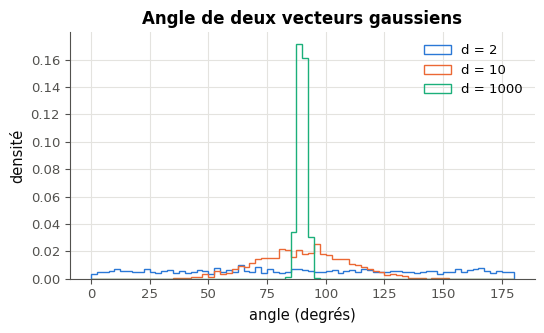

In [33]:
rng_29 = np.random.default_rng(729)
for d in (2, 10, 1000):
    X, Y = rng_29.normal(size=(2000, d)), rng_29.normal(size=(2000, d))
    cosines = np.sum(X * Y, axis=1) / (np.sqrt(np.sum(X ** 2, axis=1)) * np.sqrt(np.sum(Y ** 2, axis=1)))
    angles = np.degrees(np.arccos(np.clip(cosines, -1, 1)))
    print(f"d = {d:4d} · mean angle {angles.mean():6.2f}° · standard deviation {angles.std():6.2f}° · "
          f"share between 85° and 95°: {np.mean((angles > 85) & (angles < 95)):.3f}")
fig, ax = plt.subplots(figsize=(6, 3.2))
for d in (2, 10, 1000):
    X, Y = rng_29.normal(size=(2000, d)), rng_29.normal(size=(2000, d))
    cosines = np.sum(X * Y, axis=1) / (np.sqrt(np.sum(X ** 2, axis=1)) * np.sqrt(np.sum(Y ** 2, axis=1)))
    ax.hist(np.degrees(np.arccos(np.clip(cosines, -1, 1))), bins=np.linspace(0, 180, 73), histtype="step",
            density=True, lw=1.8, label=f"d = {d}")
ax.set(xlabel="angle (degrés)", ylabel="densité", title="Angle de deux vecteurs gaussiens")
ax.legend()
plt.show()

**Après l'expérience**, dans ta copie : relie l'écart-type mesuré en dimension 1 000 au calcul de la fiche (§7 : le cosinus est de l'ordre de $\frac{1}{\sqrt{d}}$, et près de 90°, un petit cosinus $c$ correspond à un écart d'environ $c$ radians). Pourquoi la dimension 2 se comporte-t-elle si différemment ? Qu'en conclus-tu pour des *embeddings* de dimension 768 qui n'auraient aucune structure ?

💡 a) et b) En dimension 1 000, l'angle est presque toujours à moins de 5° de 90° : l'écart-type du cosinus vaut environ $\frac{1}{\sqrt{1000}} \approx 0{,}032$, soit environ 1,8° pour l'angle, et 85° à 95° couvre près de trois écarts-types de chaque côté (plus de 99 %). c) L'écart-type diminue comme $\frac{1}{\sqrt{d}}$. d) En dimension 2, un vecteur gaussien a une direction uniforme sur le cercle : l'angle entre deux tirages est réparti uniformément entre 0° et 180°.

### Ex M07.30 — La norme d'un vecteur gaussien se concentre autour de √d 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer comment la norme d'un vecteur gaussien se rapproche de $\sqrt{d}$, et comment sa dispersion relative diminue avec la dimension.  
**Prérequis :** fiche §7 ; M02b (loi normale) ; M02c (écart-type) · **Parcours :** C

La fiche (§7) annonce que la norme d'un vecteur $\mathbf{X}$ de $\mathbb{R}^d$ à coordonnées gaussiennes indépendantes vaut environ $\sqrt{d}$, avec une dispersion qui ne grandit pas. Vérifie-le sur les échantillons fixés de la cellule ci-dessous : 2 000 vecteurs dans chaque dimension 1, 10, 100 et 1 000.

Écris `norm_summary(X)`, qui reçoit un tableau de vecteurs (un par ligne, de dimension $d$) et renvoie le couple `(moyenne des normes divisée par √d, écart-type des normes)`, deux `float` (l'écart-type avec `np.std`, `ddof = 0`). Pas de boucle : les normes de toutes les lignes s'obtiennent d'un coup (`axis=1`).

La vérification calcule :
- a) la moyenne des normes divisée par $\sqrt{1000}$, en dimension 1 000 (2 décimales) ;
- b) l'écart-type des normes en dimension 1 000 (2 décimales) ;
- c) l'écart-type des normes en dimension 1 (2 décimales) ;
- d) la pente de la droite qui ajuste $\ln\big(\frac{\text{écart-type}}{\sqrt{d}}\big)$ en fonction de $\ln d$, pour les quatre dimensions (`np.polyfit`, 1 décimale).

Dans ta copie : que dit d) de la dispersion **relative** de la norme ? Compare c) à $\sqrt{1 - \frac{2}{\pi}} \approx 0{,}603$, l'écart-type exact de $|Z|$ pour $Z$ de loi $\mathcal{N}(0, 1)$. Vers quelle valeur l'écart-type de b) semble-t-il tendre ?

In [34]:
rng_30 = np.random.default_rng(737)
DIMS_30 = [1, 10, 100, 1000]
SAMPLES_30 = {d: rng_30.normal(size=(2000, d)) for d in DIMS_30}      # 2,000 Gaussian vectors in each dimension

In [35]:
def norm_summary(X):
    """(mean of the norms of the rows of X divided by √d, standard deviation of the norms), two Python floats."""
    X = np.asarray(X, dtype=float)
    norms = np.sqrt(np.sum(X ** 2, axis=1))
    return float(norms.mean() / math.sqrt(X.shape[1])), float(norms.std())


for d in DIMS_30:
    mean_ratio, spread = norm_summary(SAMPLES_30[d])
    print(f"d = {d:4d} · mean norm / √d = {mean_ratio:.4f} · standard deviation of the norm = {spread:.4f}")
spreads_30 = [norm_summary(SAMPLES_30[d])[1] / math.sqrt(d) for d in DIMS_30]
print("slope:", np.polyfit(np.log(DIMS_30), np.log(spreads_30), 1)[0])

d =    1 · mean norm / √d = 0.7903 · standard deviation of the norm = 0.6018
d =   10 · mean norm / √d = 0.9752 · standard deviation of the norm = 0.6916
d =  100 · mean norm / √d = 0.9974 · standard deviation of the norm = 0.7139
d = 1000 · mean norm / √d = 1.0009 · standard deviation of the norm = 0.7107
slope: -0.4769482111161481


In [36]:
values_30 = {d: norm_summary(SAMPLES_30[d]) for d in DIMS_30}
wbm.record("M07.30a", values_30[1000][0], decimals=2,
           mistakes={"divise la moyenne des normes par √d": values_30[1000][0] * math.sqrt(1000)})
wbm.record("M07.30b", values_30[1000][1], decimals=2,
           mistakes={"la question demande l'écart-type des normes, sans diviser par √d": values_30[1000][1] / 1000 ** 0.5})
wbm.record("M07.30c", values_30[1][1], decimals=2)
wbm.record("M07.30d", float(np.polyfit(np.log(DIMS_30), np.log([values_30[d][1] / math.sqrt(d) for d in DIMS_30]),
                                      1)[0]), decimals=1)

WBM_ANSWER {"coarse_any": {"0": ["4314559a4639720a68600e539bc46b92d1293e89c01c88bb336c521d3592a2d5"]}, "decimals": 2, "hash": "4587ee52c08e21a2eeb39ff7d34c556fc1fd0814b889a778d0b808fa88214abb", "hash_coarse": "c3fc03c0b608c138b53fa3a7df68b894b209496a1a5ae6fae5c6419e860c64a6", "id": "M07.30a", "kind": "float", "magnitude": 0, "mistakes": {"e173ccd6e5e3ee1b1ec8108e451ba7d2eab010625abd10f44608ae8995137b45": "divise la moyenne des normes par √d"}, "sign": 1}
📝 Ex M07.30a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["74e8fb7ca0c0302809d151b98f93a627661bd828ad488dcf0eb09a6a4d846375"]}, "decimals": 2, "hash": "0500081c4b6a7ad1f3983b61b6e55bc5b7bf09d4f5b99e0b74115348deb53fe2", "hash_coarse": "46ef233608d04e1a222dcc74360b1b32744aa27b9e9d795b661ef98795604e1a", "id": "M07.30b", "kind": "float", "magnitude": -1, "mistakes": {"40526b74ab7bf03d86ac3c646c34e96c3ae8618ee9c8520569db4fb31cd1133b": "la question demande l'écart-type des normes, sans diviser par √d"}, "sign"

💡 a) La moyenne des normes divisée par $\sqrt{d}$ vaut presque 1 en dimension 1 000. b) L'écart-type de la norme reste proche de $\frac{1}{\sqrt{2}} \approx 0{,}71$, quelle que soit la dimension (dès $d \approx 10$) ; c) en dimension 1, la norme est $|Z|$, d'écart-type 0,60. d) La dispersion relative, l'écart-type divisé par $\sqrt{d}$, décroît comme $d^{-1/2}$ (pente $-0{,}5$) : en grande dimension, presque tous les vecteurs ont la même norme, à quelques pour mille près.

### Ex M07.31 — Médiane ou moyenne : le centre qui minimise les distances L1 ou leurs carrés, face à des points aberrants 🔬 ★★ ⏱️ 20 min
**Objectif :** comparer le point qui minimise la somme des distances L1 (la médiane, coordonnée par coordonnée) à celui qui minimise la somme des carrés des distances (le barycentre), et leur résistance aux points aberrants.  
**Prérequis :** fiche §3 et §6 ; Ex M07.26 · **Parcours :** C

Le barycentre minimise $\sum_i \lVert \mathbf{x}_i - \mathbf{c} \rVert_2^2$ (fiche §6). Et la somme des distances L1, $\sum_i \lVert \mathbf{x}_i - \mathbf{c} \rVert_1$ ? Elle se découpe coordonnée par coordonnée : $\sum_i \lVert \mathbf{x}_i - \mathbf{c} \rVert_1 = \sum_j \sum_i |x_{ij} - c_j|$, et chaque somme $\sum_i |x_{ij} - c_j|$ est la plus petite quand $c_j$ est une **médiane** des $x_{ij}$ (pour un nombre impair de valeurs, la valeur du milieu). Le point qui minimise la somme des distances L1 est donc la médiane, coordonnée par coordonnée.

Écris `l1_center(points)`, qui renvoie ce point en tableau NumPy (`np.median` avec le bon `axis`), et `l1_cost(points, c)`, qui renvoie $\sum_i \lVert \mathbf{x}_i - \mathbf{c} \rVert_1$ en `float`.

Les neuf points `[[1, 2], [2, 3], [3, 1], [2, 2], [4, 3], [3, 4], [1, 1], [5, 2], [2, 5]]` décrivent les positions d'un petit troupeau ; deux points aberrants `[[40, 2], [38, 1]]` y sont ajoutés (une erreur de saisie). La vérification calcule, avec ta fonction `mymath.vectors.centroid` pour le barycentre (écris d'abord M07.26) :
- a) `l1_center` des neuf points (une liste) ;
- b) leur barycentre (une liste, 4 décimales) ;
- c) `l1_center` des onze points (une liste) ;
- d) le barycentre des onze points (une liste, 4 décimales) ;
- e) la distance euclidienne dont le barycentre s'est déplacé entre b) et d) (4 décimales) ;
- f) la distance euclidienne dont la médiane s'est déplacée entre a) et c) ;
- g) le rapport `l1_cost(onze points, barycentre) / l1_cost(onze points, médiane)` (4 décimales).

Dans ta copie : pourquoi la médiane résiste-t-elle aux points aberrants, et pas le barycentre ? Lequel des deux décrit le mieux le troupeau ? Que confirme g) ?

In [37]:
def l1_center(points):
    """The coordinate-wise median of the rows of points: the point that minimises the sum of the L1 distances."""
    return np.median(np.asarray(points, dtype=float), axis=0)


def l1_cost(points, c):
    """The sum of the L1 distances from the rows of points to c, as a Python float."""
    return float(np.sum(np.abs(np.asarray(points, dtype=float) - np.asarray(c, dtype=float))))


ref_31 = wbm.load_mymath("ref")
POINTS_31, OUTLIERS_31 = np.array([[1, 2], [2, 3], [3, 1], [2, 2], [4, 3], [3, 4], [1, 1], [5, 2], [2, 5]]), np.array([[40, 2], [38, 1]])
ALL_31 = np.vstack([POINTS_31, OUTLIERS_31])
for name, pts in [("9 points", POINTS_31), ("11 points", ALL_31)]:
    print(name, "· median:", l1_center(pts), "· centroid:", ref_31.vectors.centroid(pts).round(4))
print("L1 cost ratio:", l1_cost(ALL_31, ref_31.vectors.centroid(ALL_31)) / l1_cost(ALL_31, l1_center(ALL_31)))

9 points · median: [2. 2.] · centroid: [2.5556 2.5556]
11 points · median: [3. 2.] · centroid: [9.1818 2.3636]
L1 cost ratio: 1.41699604743083


In [38]:
wbm.record("M07.31a", [2.0, 2.0], decimals=6)
wbm.record("M07.31b", [23 / 9, 23 / 9], decimals=4)
wbm.record("M07.31c", [3.0, 2.0], decimals=6,
           mistakes={"np.median doit travailler colonne par colonne : axis=0": [3.0, 3.0]})
wbm.record("M07.31d", [101 / 11, 26 / 11], decimals=4)
wbm.record("M07.31e", float(np.hypot(101 / 11 - 23 / 9, 26 / 11 - 23 / 9)), decimals=4)
wbm.record("M07.31f", 1.0, decimals=6)
wbm.record("M07.31g", float(np.sum(np.abs(ALL_31 - [101 / 11, 26 / 11])) / np.sum(np.abs(ALL_31 - [3, 2]))),
           decimals=4)

WBM_ANSWER {"decimals": 6, "element_coarse": [["ea89d26d9b07f4f71a19d453e474c0169334e8f4fe7cc128b93b7ca2c041c248"], ["a1d8a85ae93655fd80ff4a63ef83dfbd88f88d1726e8e434fcc042914d6deb02"]], "element_coarse_any": [["1d800c468dfbbf4bb74f5dead85490a47ed66fb786c4cf58a08074dab0463603", "224767b9eb2755a8bbf6cee585dbcb8b99159a8e9148cf33f4096096436502cf", "1f7d5db361eefe623ff45773dbe3afa677cc57ded289d51455dd5f15f306aad6", "57fe5efadc68e86c36f0be1745e1f59854ec44a7a355fa3a20db99516bcea0c7", "da76488fb2132daa074cfe8a70904c527d2716155a7a4609dc8f1fd6407577ca"], ["02d53a29d09bfa6935225af0bfca4ec2ae9dc7df2a17b8c10156b259702e0810", "10eac1bc9741c92bb9d1425ba6a3e9263f3354d42e3aa788c29fb1176c890b56", "41812ca66f32ce480c6553a1a242588ca3df9a72cef902ccb90eb08defc75883", "e3701c8bc53aef4abd6fdb3a8970a66f16d2afd04f53bffd742e0611224d498e", "7255b2db58cf90e2ec0338495b16c0b9bcff3975b838a9beafc02d6d702f0c2d"]], "element_hashes": ["dca4cfb19e4a1fe691e058c99698bc6de33ff520e91644288023fff489368e78", "347b058385fda1d7e

💡 Sans les points aberrants, la médiane $(2, 2)$ et le barycentre $\big(\frac{23}{9}, \frac{23}{9}\big) \approx (2{,}56 ;\ 2{,}56)$ sont proches. Avec eux, le barycentre part en $\big(\frac{101}{11}, \frac{26}{11}\big) \approx (9{,}18 ;\ 2{,}36)$, loin de tout le troupeau : il s'est déplacé d'environ 6,63. La médiane passe seulement à $(3, 2)$ : deux valeurs extrêmes décalent le rang du milieu d'une ou deux places, quelle que soit leur grandeur. Les carrés donnent un poids énorme aux grands écarts ; les valeurs absolues, non. g) confirme que la médiane minimise bien la somme des distances L1 : le barycentre fait nettement pire.

### Ex M07.32 — Les boules unités L1, L2, L∞ et Lp dans le plan 🎨 ★ ⏱️ 20 min
**Objectif :** tracer les vecteurs de norme 1 pour plusieurs normes $L^p$, en normalisant des directions, et voir les boules s'emboîter.  
**Prérequis :** fiche §3 ; R0 (matplotlib) · **Parcours :** C

Écris `draw_unit_circle(ax, p, **style)`, qui trace dans l'axe `ax` la courbe des vecteurs du plan de norme $L^p$ égale à 1. Une méthode simple : prends 400 directions $\mathbf{d}_k = (\cos t_k, \sin t_k)$ régulièrement réparties de 0 à $2\pi$, divise chacune par sa norme $L^p$ (ta fonction `norm_p`, ou la formule, avec `float("inf")` pour L∞), et relie les points obtenus par `ax.plot(xs, ys, **style)`. Les arguments `**style` (couleur, épaisseur, légende) passent tels quels à `ax.plot`.

La cellule de la figure s'en sert pour tracer, sur un même axe, les courbes de $p = 1$, $1{,}5$, $2$, $4$ et $\infty$, puis, en pointillés, celle de $p = \frac{1}{2}$ : ta fonction doit donc accepter aussi $0 < p < 1$, que `norm_p` refuse (utilise alors la formule).

Une cellule de vérification essaie ta fonction pour cinq valeurs de $p$ (la figure elle-même se juge à l'œil).

Dans ta copie : comment les courbes s'emboîtent-elles, et quelle inégalité entre normes cela traduit-il ? Pourquoi la courbe de $p = \frac{1}{2}$ montre-t-elle, d'un seul coup d'œil, que ce n'est pas une norme (pense au segment qui joint $(1, 0)$ à $(0, 1)$) ?

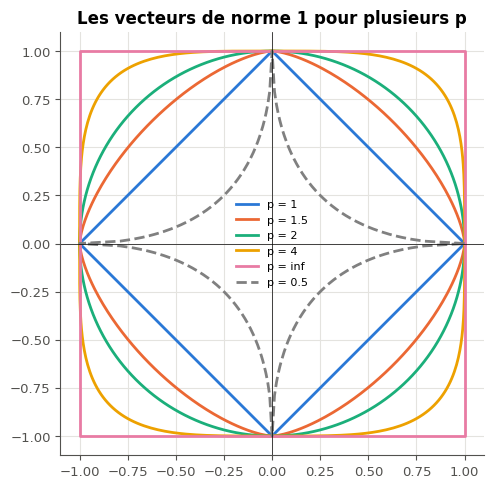

In [39]:
def draw_unit_circle(ax, p, **style):
    """In ax, the curve of the vectors of the plane whose L^p norm equals 1 (p >= 1 or float("inf"); the formula
    also for 0 < p < 1), drawn with ax.plot(..., **style)."""
    t = np.linspace(0, 2 * np.pi, 401)
    directions = np.column_stack([np.cos(t), np.sin(t)])
    if math.isinf(p):
        norms = np.max(np.abs(directions), axis=1)
    else:
        norms = np.sum(np.abs(directions) ** p, axis=1) ** (1 / p)
    points = directions / norms[:, None]
    ax.plot(points[:, 0], points[:, 1], **style)


fig, ax = plt.subplots(figsize=(5.5, 5.5))
for p, style in [(1, {}), (1.5, {}), (2, {}), (4, {}), (float("inf"), {}), (0.5, {"ls": "--", "color": "gray"})]:
    draw_unit_circle(ax, p, label=f"p = {p}", **style)
ax.axhline(0, color="black", lw=0.5)
ax.axvline(0, color="black", lw=0.5)
ax.set_aspect("equal")
ax.set(title="Les vecteurs de norme 1 pour plusieurs p")
ax.legend(fontsize=8)
plt.show()

**Vérifications automatiques** (sur cinq valeurs de $p$, chacune dans un axe neuf).

In [40]:
with checked("M07.32 vérifications"):
    import matplotlib.lines as mlines
    problems = []
    for p_t in (1, 1.5, 2, 3, float("inf")):
        fig_t, ax_t = plt.subplots()
        try:
            created = drawn(draw_unit_circle, ax_t, p_t)
        except NotImplementedError:
            plt.close(fig_t)
            raise
        lines_t = [line for line in ax_t.get_lines() if len(line.get_xdata()) > 1]
        plt.close(fig_t)
        if created:
            problems.append("draw_unit_circle ouvre sa propre figure (plt.figure ou plt.subplots) : dessine dans l'axe "
                            "reçu")
            break
        if not lines_t:
            problems.append(f"pour p = {p_t}, aucune courbe n'est tracée : ax.plot(xs, ys)")
            break
        xy = np.concatenate([np.column_stack([line.get_xdata(), line.get_ydata()]) for line in lines_t])
        xy = xy[np.isfinite(xy).all(axis=1)]
        norms_t = (np.max(np.abs(xy), axis=1) if math.isinf(p_t)
                   else np.sum(np.abs(xy) ** p_t, axis=1) ** (1 / p_t))
        angles_t = np.arctan2(xy[:, 1], xy[:, 0])
        if len(xy) < 100:
            problems.append(f"pour p = {p_t}, la courbe a {len(xy)} points : prends-en au moins 100 pour qu'elle soit "
                            "lisse")
            break
        if not np.allclose(norms_t, 1, atol=1e-6):
            problems.append(f"pour p = {p_t}, des points tracés n'ont pas une norme L{p_t} égale à 1 (de "
                            f"{norms_t.min():.3f} à {norms_t.max():.3f}) : divise chaque direction par sa norme")
            break
        if np.histogram(angles_t, bins=8, range=(-np.pi, np.pi))[0].min() == 0:
            problems.append(f"pour p = {p_t}, la courbe ne fait pas tout le tour de l'origine : prends des directions "
                            "sur tout le cercle, de 0 à 2π")
            break
    if problems:
        print("❌ Ex M07.32 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M07.32 : draw_unit_circle trace des courbes fermées dont tous les points ont la norme 1, pour "
              "cinq valeurs de p.")

✅ Ex M07.32 : draw_unit_circle trace des courbes fermées dont tous les points ont la norme 1, pour cinq valeurs de p.


💡 Les courbes s'emboîtent : celle de $p = 1$ (un losange) est à l'intérieur, celle de L∞ (un carré) à l'extérieur, et les autres passent de l'une à l'autre. Plus la norme est grande pour un même vecteur, plus sa boule unité est petite : $\lVert \mathbf{x} \rVert_\infty \le \lVert \mathbf{x} \rVert_2 \le \lVert \mathbf{x} \rVert_1$ se lit comme « le carré contient le cercle, qui contient le losange ». La courbe de $p = \frac{1}{2}$ est creusée vers l'intérieur : le milieu $(\frac{1}{2}, \frac{1}{2})$ du segment qui joint deux de ses points, $(1, 0)$ et $(0, 1)$, est à l'extérieur. Pour une norme, la boule unité est toujours convexe (M10) : c'est l'inégalité triangulaire en image.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §1, §3, §4 et §6. Trois erreurs à trouver, les normes de toutes les lignes d'un tableau, puis la médiane géométrique de 60 villes.

### Ex M07.33 — Chasse à l'erreur : une distance sans racine, un cosinus mal normalisé, une projection sur un vecteur non unitaire 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code les erreurs classiques sur les distances, les cosinus et les composantes, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §3 et §4 · **Parcours :** C

Un collègue a écrit six lignes, chacune avec un commentaire qui dit ce qu'elle doit calculer, pour $\mathbf{a} = (1, 3, -2)$ et $\mathbf{b} = (4, -1, 2)$. Trois lignes ne calculent pas ce que dit leur commentaire. **Sans exécuter de code**, trouve-les.

```python
a, b = np.array([1.0, 3.0, -2.0]), np.array([4.0, -1.0, 2.0])
dist = np.sum((a - b) ** 2)                         # (A) the Euclidean distance between a and b
dist_l1 = np.sum(np.abs(a - b))                     # (B) the L1 distance between a and b
cos = (a @ b) / np.sqrt(a @ a)                      # (C) the cosine similarity of a and b
norm_b = np.sqrt(b @ b)                             # (D) the Euclidean norm of b
comp = (b @ a) / (a @ a)                            # (E) the component of b along a (a signed length)
dist_inf = np.max(np.abs(a - b))                    # (F) the L∞ distance between a and b
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des six lignes, de (A) à (F), la bonne valeur de ce que dit son commentaire (une liste de 6 nombres, 3 décimales).

Dans ta copie : pour chaque ligne fausse, quelle erreur a été faite, et comment la corriger ? La ligne (E) calcule autre chose qu'une composante : quoi, et à quoi sert ce nombre (fiche §4) ?

In [41]:
answer_M07_33a = "ACE"
a, b = np.array([1.0, 3.0, -2.0]), np.array([4.0, -1.0, 2.0])
dist = np.sqrt(np.sum((a - b) ** 2))                # (A) the square root was missing: √41
dist_l1 = np.sum(np.abs(a - b))                     # (B) correct: 11
cos = (a @ b) / (np.sqrt(a @ a) * np.sqrt(b @ b))   # (C) divide by both norms: -3/√294
norm_b = np.sqrt(b @ b)                             # (D) correct: √21
comp = (b @ a) / np.sqrt(a @ a)                     # (E) divide by ‖a‖, not ‖a‖²: -3/√14
dist_inf = np.max(np.abs(a - b))                    # (F) correct: 4
answer_M07_33b = [float(v) for v in (dist, dist_l1, cos, norm_b, comp, dist_inf)]
print(answer_M07_33a, [round(value, 4) for value in answer_M07_33b])

ACE [6.4031, 11.0, -0.175, 4.5826, -0.8018, 4.0]


In [42]:
wbm.record("M07.33a", "ACE",
           mistakes={"il manque une ligne fautive : refais chaque calcul de distance sur un petit exemple": "CE",
                     "il manque une ligne fautive : refais chaque calcul de cosinus sur un petit exemple": "AE",
                     "il manque une ligne fautive : refais chaque calcul de composante sur un petit exemple": "AC",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABCE", "ACDE", "ACEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque calcul de distance sur un petit exemple": {"BCE", "CDE", "CEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque calcul de cosinus sur un petit exemple": {"ABE", "ADE", "AEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : refais chaque calcul de composante sur un petit exemple": {"ABC", "ACD", "ACF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "C", "E"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "D", "F", "AB", "AD", "AF", "BC", "BD", "BE", "BF", "CD", "CF", "DE", "DF", "EF", "ABD", "ABF", "ADF", "BCD", "BCF", "BDE", "BDF", "BEF", "CDF", "DEF", "ABCD", "ABCF", "ABDE", "ABDF", "ABEF", "ACDF", "ADEF", "BCDE", "BCDF", "BCEF", "BDEF", "CDEF", "ABCDF", "ABDEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDE", "ABCEF", "ACDEF", "ABCDEF"}})
wbm.record("M07.33b", [41 ** 0.5, 11, -3 / 294 ** 0.5, 21 ** 0.5, -3 / 14 ** 0.5, 4], decimals=3,
           mistakes={"(A) : la distance euclidienne est la racine de la somme des carrés":
                         [41, 11, -3 / 294 ** 0.5, 21 ** 0.5, -3 / 14 ** 0.5, 4],
                     "(C) : le cosinus divise par le produit des deux normes":
                         [41 ** 0.5, 11, -3 / 14 ** 0.5, 21 ** 0.5, -3 / 14 ** 0.5, 4],
                     "(E) : la composante divise par ‖a‖, pas par ‖a‖²":
                         [41 ** 0.5, 11, -3 / 294 ** 0.5, 21 ** 0.5, -3 / 14, 4]})

WBM_ANSWER {"hash": "b7d6f47c3018378baf1f72196e793c5870b1260657d7e4d634c469497842d456", "id": "M07.33a", "kind": "str", "mistakes": {"07f3fe79a33364b043b989e26f45c4aad84e2a3bf2492adc0b1817e8ca0d8332": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "09a95fee3029adbe7022f90ba283cc223d8f08f25a79e325e6c55e5f57b0a791": "il manque une ligne fautive : refais chaque calcul de composante sur un petit exemple", "09dd0cbe14a28e5d36f10ce10603202e8b8f45072a15bfc1f725d7af11b2b7b4": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0d022655be06fba367accbf0643ec1e3273c40a0dc562d266170f657cba979b4": "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple", "11df2d1b746e1af3d783ecd913fe754bf1f0dc5eafbc863e7b6f4644fb976105": "il manque une ligne fautive : refais chaque calcul de cosinus sur un petit exemple", "14cc691403fbe039341f6be

WBM_ANSWER {"decimals": 3, "element_coarse": [["c2068f4a41904d510344996ed0a91a31b93f134cdc340156dc698addb43b2bd0"], ["4667dd2b6dc72f74065b337233d47f6b582337ce3190916cceeeb1d107aaee0d"], ["7558e5902cdc6b029767cd8e9774e0dba75ec2964b58f3fb5344e1a637979b78"], ["2bca6097afbeef3adb6caa61df83c6ab66fabb191ebfb2488aaac556f91377ab"], ["9dd210f56c8bff24435e967e5bab45418d71fd32bb3625c24c3922bf6fa5bf5d"], ["0c1c7e9bfd68cf749cc47c0c3cf8b91ff00c511d390ecbdc4c5b279a0cdbe536"]], "element_coarse_any": [["4904158630d6aa8bc5897817800f374be246f2ed039519d2c2a0a916cba3cd9a", "5ed5485919c0b8b831c3e85dac6910e403cc0bcf543fac561c0571ec7f0552aa"], ["8b9cf0da10ec8c7a181ae7e0475d05f1af4dc0b0d0a6a4017e944a568fa013d4", "2572b22db59e7cd678a66d72dbab6433ad48340b4ff82b220c758fb76d686c50"], ["a0336c0efd68fe1ae71bb5a53e6143d28cc76f62c00e8648f0806c09a5bc87fa"], ["2948a1f9312cacd54ac4bab3d324aafb2e67029c5bced16c2308e2c728a82b5c", "42b26adc71ac6f921e8db0ec246cfe2ff70c2cbec410ef9a5372b1d1330768d1"], ["982b7e349063ad8ecd0d7768

💡 (A) oublie la racine : la somme des carrés vaut 41, la distance $\sqrt{41} \approx 6{,}403$. (C) ne divise que par $\lVert \mathbf{a} \rVert$ : avec $\mathbf{a} \cdot \mathbf{b} = 4 - 3 - 4 = -3$, le cosinus vaut $\frac{-3}{\sqrt{14}\sqrt{21}} \approx -0{,}175$. (E) divise par $\lVert \mathbf{a} \rVert^2$ : c'est le **coefficient** $t$ de la projection, $\mathbf{p} = t\,\mathbf{a}$ ; la composante (une longueur avec un signe) vaut $\frac{-3}{\sqrt{14}} \approx -0{,}802$. (B), (D) et (F) sont justes : 11, $\sqrt{21} \approx 4{,}583$ et 4.

### Ex M07.34 — Les normes de toutes les lignes d'un tableau : axis, keepdims et broadcasting 🛠️ ★ ⏱️ 15 min
**Objectif :** calculer les normes de toutes les lignes d'un tableau et normaliser chaque ligne d'un coup, sans boucle, avec `axis` et `keepdims`.  
**Prérequis :** fiche §1 et §3 ; 0A (broadcasting) · **Parcours :** C

Un dataset est un tableau `X` de forme `(n, p)`, un exemple par ligne. Calculer la norme de chaque exemple, ou le normaliser, se fait d'un coup avec NumPy :
- `np.sum(A, axis=1)` additionne chaque **ligne** (on « écrase » l'axe des colonnes) et rend un tableau de forme `(n,)` ;
- avec `keepdims=True`, le résultat garde la forme `(n, 1)` : une colonne, qui se divise ligne par ligne par le **broadcasting** (`X / colonne` divise chaque ligne par son nombre).

Écris, **sans boucle** :
- `row_norms(X, p=2)`, qui renvoie le tableau des normes $L^p$ des lignes de `X` (`p = float("inf")` pour L∞) ;
- `normalize_rows(X)`, qui renvoie le tableau de même forme dont chaque ligne est divisée par sa norme L2 ; une ligne nulle reste nulle, sans division par zéro (astuce : divise par `np.where(norms > 0, norms, 1.0)`, puis remets 0 sur les lignes nulles avec un second `np.where`).

Une cellule de vérification compare tes fonctions à une boucle (ligne nulle comprise) et vérifie qu'elles n'en contiennent pas ; une autre compare les temps de calcul.

Dans ta copie : que donnerait `np.sum(X ** 2, axis=0)` ? Pourquoi `X / row_norms(X)` (sans `keepdims`) échoue-t-il, ou se trompe-t-il quand `X` est carré ? Combien de fois plus rapide est `row_norms` que la boucle ?

In [43]:
def row_norms(X, p=2):
    """The L^p norms of the rows of X (p = float("inf") for L∞), without a Python loop."""
    A = np.abs(np.asarray(X, dtype=float))
    if math.isinf(p):
        return np.max(A, axis=1)
    return np.sum(A ** p, axis=1) ** (1 / p)


def normalize_rows(X):
    """Each row of X divided by its L2 norm (a zero row stays zero), without a Python loop."""
    X = np.asarray(X, dtype=float)
    norms = np.sqrt(np.sum(X ** 2, axis=1, keepdims=True))
    return np.where(norms > 0, X / np.where(norms > 0, norms, 1.0), 0.0)

In [44]:
with checked("M07.34 vérifications"):
    import ast
    import inspect
    import textwrap
    problems = []
    rng_t = np.random.default_rng(734)
    X_t = rng_t.normal(size=(7, 5))
    X_t[3] = 0.0                                                     # a zero row
    for p_t in (1, 2, float("inf")):
        expected = np.array([max(abs(v) for v in row) if math.isinf(p_t) else sum(abs(v) ** p_t for v in row) ** (1 / p_t)
                             for row in X_t])
        got = row_norms(X_t, p_t)
        if got is None:
            problems.append("row_norms ne renvoie rien : il manque return")
            break
        got = np.asarray(got)
        if got.shape != (7,):
            problems.append(f"row_norms renvoie la forme {got.shape} : une norme par ligne, de forme (7,)"
                            + (" ; somme sur axis=1, les colonnes" if got.shape == (5,) else ""))
            break
        if not np.allclose(got, expected, atol=1e-12):
            problems.append(f"pour p = {p_t}, row_norms ne donne pas la norme de chaque ligne")
            break
    if not problems:
        unit_t = normalize_rows(X_t)
        if unit_t is None:
            problems.append("normalize_rows ne renvoie rien : il manque return")
        else:
            unit_t = np.asarray(unit_t)
            if unit_t.shape != X_t.shape:
                problems.append(f"normalize_rows renvoie la forme {unit_t.shape}, pas {X_t.shape} : keepdims=True garde "
                                "une colonne pour le broadcasting")
            elif not np.all(np.isfinite(unit_t)):
                problems.append("normalize_rows produit des nan pour la ligne nulle : laisse-la à zéro (np.where)")
            elif not np.allclose(np.delete(np.sqrt(np.sum(unit_t ** 2, axis=1)), 3), 1, atol=1e-12):
                problems.append("les lignes non nulles de normalize_rows n'ont pas la norme 1")
            elif not np.allclose(unit_t[3], 0):
                problems.append("la ligne nulle doit rester nulle")
            elif not np.allclose(unit_t * np.sqrt(np.sum(X_t ** 2, axis=1, keepdims=True)), X_t, atol=1e-12):
                problems.append("normalize_rows doit garder la direction de chaque ligne")
    if not problems:
        for name_t, function_t in [("row_norms", row_norms), ("normalize_rows", normalize_rows)]:
            try:
                tree_t = ast.parse(textwrap.dedent(inspect.getsource(function_t)))
            except (OSError, TypeError, SyntaxError):
                continue
            if any(isinstance(node, (ast.For, ast.While, ast.comprehension)) for node in ast.walk(tree_t)):
                problems.append(f"{name_t} contient une boucle : l'exercice demande de calculer toutes les lignes d'un "
                                "coup (axis, keepdims)")
                break
    if problems:
        print("❌ Ex M07.34 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M07.34 : row_norms et normalize_rows sont justes, sans boucle, ligne nulle comprise.")

✅ Ex M07.34 : row_norms et normalize_rows sont justes, sans boucle, ligne nulle comprise.


**Le temps de calcul** (cette cellule utilise ta fonction).

In [45]:
import time
X_big = np.random.default_rng(34).normal(size=(20000, 64))
start = time.perf_counter()
loop = np.array([math.sqrt(sum(v * v for v in row)) for row in X_big])
loop_seconds = time.perf_counter() - start
start = time.perf_counter()
fast = np.asarray(row_norms(X_big, 2))
fast_seconds = time.perf_counter() - start
print(f"loop: {loop_seconds:.3f} s · row_norms: {fast_seconds:.4f} s · same values: {np.allclose(loop, fast)}")

loop: 0.121 s · row_norms: 0.0088 s · same values: True


💡 `np.sum(X ** 2, axis=0)` additionne chaque **colonne** : un nombre par feature, pas par exemple. Sans `keepdims`, les normes ont la forme `(n,)`, que NumPy aligne sur la **dernière** dimension de `X` : une erreur de forme si $p \ne n$, et, pire, une division des **colonnes** sans message d'erreur quand `X` est carré. La ligne nulle demande un `np.where` : $\frac{0}{0}$ donnerait `nan`. Sur 20 000 lignes, la version vectorisée est en général une dizaine de fois plus rapide que la boucle, souvent davantage.

### Ex M07.35 — Défi : le point qui minimise la somme des distances (non au carré) à 60 villes, à 0,1 % près 🏆 ★★★ ⏱️ 30 min
**Objectif :** trouver numériquement le point qui minimise la somme des distances euclidiennes à des points donnés (la médiane géométrique), et voir qu'il n'est ni le barycentre ni la médiane coordonnée par coordonnée.  
**Prérequis :** fiche §3 et §6 ; Ex M07.26 et M07.31 · **Parcours :** C

Une entreprise veut construire un entrepôt qui dessert 60 villes, et minimiser la **somme des distances** (pas de leurs carrés) de l'entrepôt aux villes, $\sum_i \lVert \mathbf{x}_i - \mathbf{c} \rVert$ (la fonction `total_distance` ci-dessous). Ce point s'appelle la **médiane géométrique**. Il n'a pas de formule : le barycentre minimise la somme des **carrés** (fiche §6), et la médiane coordonnée par coordonnée minimise la somme des distances **L1** (M07.31), mais aucun des deux ne convient ici.

Écris `geometric_median(points)`, qui renvoie le point `[x, y]` (deux nombres). **L'objectif** : une somme des distances à 0,1 % au plus du minimum, en moins de 5 secondes, sur les villes `CITIES_35` et sur quatre autres ensembles de villes. NumPy suffit ; `scipy.optimize` est interdit (c'est lui que la vérification utilise pour trouver le minimum).

La vérification essaie ta fonction sur cinq ensembles de villes ; une dernière cellule enregistre si l'objectif est atteint pour `CITIES_35`.

Dans ta copie : de combien (en %) le barycentre et la médiane coordonnée par coordonnée manquent-ils l'objectif pour `CITIES_35` ? Explique l'idée de ta méthode. Le point trouvé est-il plus proche du groupe de 26 villes ou des deux autres, et pourquoi ?

In [46]:
def make_cities(seed, angle):
    """60 towns in three groups of 26, 20 and 14, rotated by angle degrees (coordinates in km, rounded to 10 m)."""
    rng = np.random.default_rng(seed)
    centers, sizes = np.array([[0.0, 0.0], [10.0, 1.0], [4.0, 8.0]]), [26, 20, 14]
    towns = np.vstack([rng.normal(c, 1.2, size=(k, 2)) for c, k in zip(centers, sizes)])
    t = np.radians(angle)
    rotation = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    return np.round(towns @ rotation.T + [5.0, 3.0], 2)


def total_distance(points, c):
    """Σ ‖x_i − c‖: the sum of the (non-squared) Euclidean distances from the rows of points to c."""
    return float(np.sum(np.sqrt(np.sum((np.asarray(points, dtype=float) - np.asarray(c, dtype=float)) ** 2, axis=1))))


CITIES_35 = make_cities(735, 20)

In [47]:
def geometric_median(points, iterations=500):
    """The point [x, y] that minimises the sum of the Euclidean distances to the rows of points (within 0.1 %).

    Weiszfeld's algorithm: start from the centroid, then replace c by the centroid of the points weighted by the
    inverse of their distances to c (a point far away pulls less than in the centroid)."""
    P = np.asarray(points, dtype=float)
    c = P.mean(axis=0)
    for _ in range(iterations):
        d = np.sqrt(np.sum((P - c) ** 2, axis=1))
        d = np.maximum(d, 1e-12)                       # c on a town: avoid a division by zero
        weights = 1 / d
        c = np.sum(weights[:, None] * P, axis=0) / np.sum(weights)
    return [float(c[0]), float(c[1])]


g_35 = geometric_median(CITIES_35)
best_35 = total_distance(CITIES_35, g_35)
print("geometric median:", np.round(g_35, 3), "· sum of distances:", round(best_35, 3))
print("centroid: +", round(100 * (total_distance(CITIES_35, CITIES_35.mean(axis=0)) / best_35 - 1), 2), "%",
      "· coordinate-wise median: +", round(100 * (total_distance(CITIES_35, np.median(CITIES_35, axis=0)) / best_35 - 1),
                                           2), "%")

geometric median: [7.713 5.761] · sum of distances: 328.248
centroid: + 0.6 % · coordinate-wise median: + 1.91 %


In [48]:
wbm.record("M07.35", True,
           mistakes={"ton point fait plus de 0,1 % de plus que le minimum pour CITIES_35 : la cellule du défi dit de "
                     "combien": False})

WBM_ANSWER {"hash": "7caf74af4ca0b6ab8a45684bca8ee7709ad45460c51b0dab98e02e247da6b08e", "id": "M07.35", "kind": "bool", "mistakes": {"749585d83d8c68622e9f145f59cc383ad370141edbabb5ef17c6709fcf8e8919": "ton point fait plus de 0,1 % de plus que le minimum pour CITIES_35 : la cellule du défi dit de combien"}}
📝 Ex M07.35 : réponse enregistrée (bool).


In [49]:
with checked("M07.35 défi"):
    import time
    from scipy.optimize import minimize
    problems, worst_ratio, slowest, worst_kind = [], 0.0, 0.0, ""
    for seed_t, angle_t in [(735, 20), (11, 75), (12, 140), (13, 200), (14, 290)]:
        towns_t = make_cities(seed_t, angle_t)
        best_t = minimize(lambda c: total_distance(towns_t, c), np.median(towns_t, axis=0), method="Nelder-Mead",
                          options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 20000}).fun
        start_t = time.perf_counter()
        try:
            got_t = geometric_median(towns_t)
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            problems.append(f"geometric_median lève {type(exc).__name__} ({exc})")
            break
        slowest = max(slowest, time.perf_counter() - start_t)
        if got_t is None or np.shape(got_t) != (2,) or not np.all(np.isfinite(np.asarray(got_t, dtype=float))):
            problems.append("geometric_median doit renvoyer un point du plan : deux nombres finis")
            break
        ratio_t = total_distance(towns_t, got_t) / best_t
        if ratio_t > worst_ratio:
            worst_ratio, g_t = ratio_t, np.asarray(got_t, dtype=float)
            if np.allclose(g_t, towns_t.mean(axis=0), atol=1e-6):
                worst_kind = "le barycentre, qui ne minimise que la somme des carrés des distances"
            elif np.allclose(g_t, np.median(towns_t, axis=0), atol=1e-6):
                worst_kind = "la médiane coordonnée par coordonnée, qui minimise la somme des distances L1"
            else:
                worst_kind = ""
    if problems:
        print("❌ Ex M07.35 : " + problems[0] + ".")
    elif worst_ratio > 1.001:
        detail = (f"Ton point est {worst_kind}." if worst_kind else
                  "Ta méthode approche le minimum sans l'atteindre : vérifie chaque étape, ou itère davantage.")
        print(f"❌ Ex M07.35 : ton point fait jusqu'à {100 * (worst_ratio - 1):.3f} % de plus que le minimum (objectif : "
              f"0,1 % au plus). {detail}")
    elif slowest > 5:
        print(f"❌ Ex M07.35 : objectif atteint, mais en {slowest:.1f} s pour un ensemble de villes (objectif : 5 s).")
    else:
        print(f"✅ Ex M07.35 : défi réussi, à {100 * (worst_ratio - 1):.4f} % du minimum au pire, sur cinq ensembles de "
              "villes.")

✅ Ex M07.35 : défi réussi, à 0.0000 % du minimum au pire, sur cinq ensembles de villes.


💡 Le barycentre manque l'objectif d'environ 0,6 %, et la médiane coordonnée par coordonnée de près de 2 %. L'algorithme de Weiszfeld (1937) part du barycentre, puis remplace $\mathbf{c}$ par le barycentre des villes pondérées par $\frac{1}{\lVert \mathbf{x}_i - \mathbf{c} \rVert}$ : une ville lointaine tire moins fort que dans le barycentre, où chaque ville tire proportionnellement à sa distance. Le point fixe annule le gradient de la somme des distances, $\sum_i \frac{\mathbf{c} - \mathbf{x}_i}{\lVert \mathbf{c} - \mathbf{x}_i \rVert}$, une somme de vecteurs unitaires. Le point trouvé est plus près du groupe de 26 villes que le barycentre (à environ 3,8 km de son centre, contre 4,9 km) : avec les distances non élevées au carré, chaque ville « vote » avec une force égale, et le groupe le plus nombreux l'emporte.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer un produit scalaire, les normes L1, L2 et L∞ et une distance en dimension $n$ ?
2. Sais-tu calculer un cosinus et une projection, et démontrer l'inégalité de Cauchy-Schwarz ?
3. Sais-tu dire de quel côté d'un hyperplan est un point, et calculer sa distance à l'hyperplan ?
4. Sais-tu pourquoi le barycentre minimise l'inertie, et ce que font k-means, la silhouette et k-means++ ?
5. Sais-tu ce qui change en grande dimension ?

**La suite** : le chapitre 7 de workbookIA (classification, k-means, malédiction de la dimension), puis M08, les tests statistiques.